# Inland Excess Water (IEW) Monitoring — Temporal-Radar Former (TRF)

**Notebook 11. A different architecture from notebooks 01–10.**

Every model so far (U-Net, U-Net++, RUPNet, TransUNet, SegFormer, Spectral ResUNet) looked at **one date** of imagery through a **small window** (64–128 px, under 1.3 km) and classified each pixel from that single snapshot. Notebook 10 got water and not-affected to about 98 F1, but the three soil-severity classes stayed at 60–71 F1 and vegetation-affected at about 67 F1 (test set, calibrated).

Those classes describe **how wet the soil is and how long it has been wet**. That depends on things a single optical snapshot can't show:

| What matters physically | Where the signal is | Did notebooks 01–10 see it? |
|---|---|---|
| Soil moisture | Sentinel-1 radar backscatter (VV/VH) responds directly to surface moisture | Only notebook 10, as 3 extra input channels |
| History: flooded last month and still drying vs. dry for months | Earlier acquisitions of the **same site** | **No** |
| Landscape position: water collects in depressions and drainage lines | Spatial context of several km | **No**, patches were 0.6–1.3 km |
| Clouds on the target date | Radar sees through clouds; earlier dates fill the gap | **No** for training (only the separate notebook 07 gap-filling step) |

TRF changes **what the network sees**, not just the network shape.

### The four ideas

1. **Time series as input.** Each training sample is the target date **plus up to 3 earlier acquisitions of the same site** (within 120 days), each with Sentinel-2 *and* Sentinel-1. Only the *imagery* of earlier dates is used, never their labels, so this is legitimate at test time too. A real monitoring system always has the previous acquisitions.
2. **Per-pixel temporal + cross-modal attention.** At every location (1/4 resolution) the network builds a short sequence of tokens: `[S2 date0, S2 date-1, ..., S1 date0, S1 date-1, ...]`. Each token carries a modality embedding and a time embedding (days before the target date, plus season). A small transformer lets every token attend to every other one. Cloudy, missing or no-data tokens are **masked out of attention**, so the model automatically falls back to radar and older dates where the target date is cloudy.
3. **Large spatial context.** The fused map goes through a ConvNeXt encoder (1/4 → 1/32) that ends in a **global self-attention block**. Training patches are 256 px (2.56 km), and full-scene inference uses 640 px windows (6.4 km), so the model can reason about landscape position.
4. **An output that matches the class structure,** with three heads trained jointly:
   - a normal 6-class head;
   - a coarse 4-class head: water / affected soil / affected vegetation / not affected;
   - an **ordinal severity head** for soil only: P(at least moderate), P(at least serious). This encodes slight < moderate < serious, so confusing serious with slight costs more than serious with moderate.

   The final prediction blends the flat 6-class probabilities with the hierarchical ones (coarse × severity). The blend weight and a per-class logit bias are chosen on held-out training scenes, never on test.

### Two-stage training

| Stage | What | Labels used | Why |
|---|---|---|---|
| **1. Self-supervised pre-training** | Hide 50% of the target date's pixels in 16×16 blocks (and, in 25% of samples, the *whole* target optical image), then reconstruct them from radar + history + visible neighbours | **None** | 14 labelled scenes is very little. Imagery has hundreds of millions of unlabelled pixels. Rebuilding optical from radar + history is exactly the skill needed under clouds. |
| **2. Supervised fine-tuning** | All heads, class-aware patch sampling, ordinal label smoothing, EMA weights, lower learning rate for the pre-trained encoder | Train-split GT | Turns the pre-trained representation into the 6-class map |

### What else differs from notebook 10

| | Notebook 10 (Spectral ResUNet) | Notebook 11 (TRF) |
|---|---|---|
| Dates per sample | 1 | 1 + up to 3 earlier dates |
| Radar usage | Concatenated channels | Separate token stream, cross-attention, survives clouds |
| Patch / context | 96 px (0.96 km) | 256 px train (2.56 km), 640 px inference windows |
| Core | Residual U-Net + 1×1 spectral branch | Per-pixel temporal transformer → ConvNeXt + global attention → FPN decoder |
| Normalisation | BatchNorm | GroupNorm/LayerNorm (stable with missing dates in a batch) |
| Pre-training | None | Masked multi-modal reconstruction |
| Output | Flat softmax | Flat + hierarchical + ordinal, blended |
| Loss | CE + Dice | Ordinal-smoothed CE + Dice + deep supervision + coarse CE + ordinal BCE |
| Weights used for eval | Last-best raw weights | EMA (exponential moving average) weights |
| Test-time augmentation | Horizontal flip | All 8 flips/rotations (D4) |

### Honest expectations

Water and not-affected are already at about 98 F1, and this notebook should keep them there. The aim is a clear gain on the soil-severity and vegetation classes. **90+ F1 on every class is not guaranteed.** The boundaries between serious / moderate / slight soil in the ground truth are themselves fuzzy, and the paper's own best model reached 81 F1 averaged over classes 2–6. Record whatever this notebook produces honestly in §12. The ablation in §9 shows how much the time series and the radar each contribute, which is useful for the report in any case.

### How to run (on a GPU machine)

1. **Python packages:** `torch>=2.1` (CUDA build), `rasterio`, `numpy`, `pyyaml`, `matplotlib`.
2. **Dataset path:** edit `dataset_root` in `configs/data.yaml` to where the IEW-Seg tifs are on that machine. Expected layout: `<root>/tifs/{Train,Test}/{S2,S1,GT}/<SITE>_<YYYYMMDD>.tif` (or the same without the `tifs/` level).
3. **First do a dry run:** set `QUICK_TEST = True` in §1 and run all cells. It trains for one tiny epoch of each stage, evaluates 2 tiles per scene, and writes `*_quicktest*` checkpoints that never overwrite real ones. If it finishes without errors, set `QUICK_TEST = False`, then *Restart & Run All*.
4. **GPU memory:** the defaults (`PATCH=256`, `BATCH_SIZE=8`, mixed precision) are sized for about 8–12 GB of VRAM. If you get *CUDA out of memory*, set `BATCH_SIZE = 4` first, then `PATCH = 192` (must stay divisible by 32).
5. **Interruptions:** both stages save a checkpoint every epoch and resume automatically (`RESUME = True`).
6. **CPU:** this model is far too heavy to train on a CPU; use a CUDA GPU.

### Outputs

- `outputs/checkpoints/trf_ssl.pt`: Stage 1 weights
- `outputs/checkpoints/trf_best.pt`: best EMA weights from Stage 2 (selected on held-out train scenes)
- `outputs/checkpoints/trf_last.pt`: resumable training state
- `outputs/checkpoints/trf_calibration.json`: head-blend weight + per-class logit bias
- `outputs/trf_results.json`: test metrics, per-scene scores and ablation numbers for the report

## Architecture at a glance

Shapes for one training batch: `B=8`, `T=4` dates, `P=256`, `d=96`.

```
 per date t = 0..3 (0 = target date, 1..3 = earlier acquisitions, missing dates = zeros + valid=0)

 S2_t  (19 ch: 11 bands + 6 indices + cloud score + valid flag) ──► DateStem_S2 ──┬─► half-res  48 ch @128²   (target date only → decoder skip)
                                                                   (shared over t) └─► quarter  96 ch @ 64²
 S1_t  ( 4 ch: VV, VH, ratio + valid flag)                     ──► DateStem_S1 ──┬─► half-res  48 ch @128²
                                                                                    └─► quarter  96 ch @ 64²

 ──────────── per-pixel temporal / cross-modal fusion (at 64×64 locations) ────────────
   tokens per location: 4 S2 tokens + 4 S1 tokens  (8 × 96)
     + modality embedding + time embedding (days before target, season) + "target date" embedding
   2 × transformer layer (4 heads); cloudy / no-data / missing tokens masked out
   output = [target-S2 token ; attention-pooled summary] → 96 ch
                                       fused map (B, 96, 64, 64)

 ──────────── spatial encoder (ConvNeXt) ────────────
   1/4  : 2 blocks, 96 ch    @ 64²
   1/8  : 2 blocks, 192 ch   @ 32²
   1/16 : 4 blocks, 288 ch   @ 16²
   1/32 : 2 blocks, 384 ch   @  8²  + 2 global self-attention layers over all 64 tokens

 ──────────── decoder ────────────
   FPN (all 4 scales → 128 ch @ 1/4) ──► aux 6-class head (deep supervision)
   up ×2, + target S2/S1 half-res stem features            → 96 ch @ 1/2
   up ×2, + full-res branch on target date (1×1 spectral MLP ‖ 3×3 local conv) → 64 ch @ full res

 ──────────── heads (full resolution) ────────────
   main     6 logits   (flat classes)
   coarse   4 logits   water / affected soil / affected vegetation / not affected
   ordinal  2 logits   z1 → P(soil ≥ moderate), z2 → P(serious | ≥ moderate)
   recon   20 ch       Stage 1 only: rebuilds the masked target-date S2 + S1 features
```

**How the ordinal head becomes class probabilities:** `P(≥moderate) = σ(z1)` and `P(serious) = σ(z1)·σ(z2)`. Then `P(slight) = 1 − σ(z1)` and `P(moderate) = σ(z1) − σ(z1)·σ(z2)`. All three are non-negative and sum to 1 by construction. Hierarchical probabilities = `[coarse_water, coarse_soil·P(serious), coarse_soil·P(moderate), coarse_soil·P(slight), coarse_veg, coarse_not]`. The final map uses `(1−α)·flat + α·hierarchical`, with α picked on held-out training scenes.

**Roughly 10–13 M parameters**; the exact count is printed by the smoke test in §4.

## 1. Imports and configuration
All knobs are in this one cell.

In [1]:
import copy
import datetime
import json
import math
import time
from pathlib import Path

import numpy as np
import yaml
import rasterio
from rasterio.windows import Window
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

QUICK_TEST = False        # True = tiny dry run of the whole notebook (writes *_quicktest* checkpoints only)

SEED            = 0
PATCH           = 192      # training patch size, must be divisible by 32
GRID_STRIDE     = 64        # candidate patch locations are indexed on this grid
N_CONTEXT       = 3         # earlier acquisitions of the same site fed as context
MAX_GAP_DAYS    = 120       # ignore context dates older than this
CONTEXT_DROPOUT = 0.3       # training: drop each context date with this probability (robustness)
GAIN_JITTER     = 0.05      # training: per-band, per-date multiplicative S2 gain noise (atmosphere)
BATCH_SIZE      = 4
NUM_WORKERS     = 0         # keep 0 on Windows + Jupyter; 4 is fine on Linux
USE_AMP         = True      # mixed precision on CUDA
RESUME          = True

# Stage 1 - self-supervised masked reconstruction (no labels)
RUN_SSL               = True
SSL_EPOCHS            = 15
SSL_SAMPLES_PER_EPOCH = 3000
SSL_LR                = 1e-3
SSL_MASK_RATIO        = 0.5     # share of 16x16 blocks hidden on the target date (S2)
SSL_DROP_S2_PROB      = 0.25    # share of samples whose whole target-date S2 is hidden
SSL_BLOCK             = 16
SSL_USE_TEST_IMAGERY  = False   # True = also pre-train on Test-split *imagery* (never labels). Transductive - say so in the report if enabled.

# Stage 2 - supervised fine-tuning
EPOCHS            = 40
SAMPLES_PER_EPOCH = 3000
VAL_PATCHES       = 400
MAX_LR            = 6e-4
ENCODER_LR_SCALE  = 0.3     # pre-trained stems/temporal/encoder learn slower than the decoder/heads
WEIGHT_DECAY      = 0.05
WARMUP_FRAC       = 0.05
EMA_DECAY         = 0.999
ORDINAL_SMOOTH    = 0.10    # label mass moved to the neighbouring soil-severity class

# Inference
TILE, MARGIN = 512, 64      # predict 512x512 centres from 640x640 windows
TTA          = "d4"         # "none" | "flip" | "d4" (all 8 flips/rotations)

# Same held-out training scenes as notebook 10 (checkpoint selection + calibration), so results are comparable.
VAL_SCENES = ["BNPI_20230208", "KNPI_20220310"]

# Share of each epoch's patches drawn from locations containing a given class (compact ids).
CLASS_SHARE = {0: 0.05, 1: 0.20, 2: 0.20, 3: 0.10, 4: 0.10}

MAX_TILES = None
if QUICK_TEST:
    SSL_EPOCHS, SSL_SAMPLES_PER_EPOCH = 1, 32
    EPOCHS, SAMPLES_PER_EPOCH, VAL_PATCHES = 1, 32, 16
    TTA, MAX_TILES = "none", 2

TAG       = "trf" + ("_quicktest" if QUICK_TEST else "")
CKPT_DIR  = Path("outputs/checkpoints")
CKPT_DIR.mkdir(parents=True, exist_ok=True)
SSL_PATH  = CKPT_DIR / f"{TAG}_ssl.pt"
SSL_LAST  = CKPT_DIR / f"{TAG}_ssl_last.pt"
BEST_PATH = CKPT_DIR / f"{TAG}_best.pt"
LAST_PATH = CKPT_DIR / f"{TAG}_last.pt"
CAL_PATH  = CKPT_DIR / f"{TAG}_calibration.json"
RESULTS_PATH = Path("outputs") / f"{TAG}_results.json"

assert PATCH % 32 == 0 and (TILE + 2 * MARGIN) % 32 == 0, "sizes must be divisible by 32"

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ON = USE_AMP and device.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (AMP_ON and torch.cuda.is_bf16_supported()) else torch.float16
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
    print(f"GPU: {torch.cuda.get_device_name(0)} | "
          f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB")
else:
    print("WARNING: no CUDA GPU found - this notebook is meant for a GPU. Use QUICK_TEST only on CPU.")
print(f"PyTorch {torch.__version__} | device {device} | AMP {AMP_ON} ({AMP_DTYPE if AMP_ON else '-'})")


def autocast():
    return torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=AMP_ON)


def make_scaler():
    enabled = AMP_ON and AMP_DTYPE == torch.float16
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)

GPU: NVIDIA GeForce RTX 4050 Laptop GPU | 6.0 GB
PyTorch 2.6.0+cu124 | device cuda | AMP True (torch.bfloat16)


## 2. Data: scenes, per-date features and the per-site timeline

- **Features per date.** Sentinel-2 gives 11 standardised bands, the same 6 spectral indices as notebook 10 (NDVI, NDMI, NDWI, MNDWI, SWIR1-red, SWIR ratio), a simple brightness-based cloud/haze score, and a **valid flag**. Sentinel-1 gives standardised VV, VH, the ratio, and a valid flag. No-data pixels are zeroed and flagged invalid.
- **Timeline.** Scenes from *both* splits are grouped per site and sorted by date. For every target scene, the context is the up-to-3 most recent **earlier** scenes of the same site within `MAX_GAP_DAYS`, on the same pixel grid. Only their imagery is read; **context-scene GT is never touched**. This is enforced because GT is loaded lazily and only for target scenes.
- The class mapping (`raw 2..7 → 0..5`, everything else → ignore) and the normalisation statistics are identical to notebook 10.

In [2]:
with open("configs/data.yaml", "r") as f:
    config = yaml.safe_load(f)

dataset_root = Path(config["dataset_root"])
LOCAL_ROOT = Path("tifs")
if not dataset_root.exists() and LOCAL_ROOT.exists():
    dataset_root = LOCAL_ROOT
assert dataset_root.exists(), f"Dataset not found at {dataset_root} - edit dataset_root in configs/data.yaml"
print(f"Dataset root: {dataset_root}")

IGNORE = 255
NUM_CLASSES = 6
CLASS_NAMES = [
    "Open surface water (raw 2)",
    "Soil seriously affected (raw 3)",
    "Soil moderately affected (raw 4)",
    "Soil slightly affected (raw 5)",
    "Vegetation affected (raw 6)",
    "Not affected (raw 7)",
]
GT_LUT = np.full(256, IGNORE, dtype=np.uint8)
for raw, cls in {2: 0, 3: 1, 4: 2, 5: 3, 6: 4, 7: 5}.items():
    GT_LUT[raw] = cls

# Band order: B01 B02 B03 B04 B05 B06 B07 B08 B8A B11 B12
S2_MEAN = np.array([0.0436, 0.0557, 0.0723, 0.0838, 0.1151, 0.1598,
                    0.1800, 0.1974, 0.2004, 0.2233, 0.1706], dtype=np.float32)
S2_STD  = np.array([0.0182, 0.0233, 0.0272, 0.0340, 0.0380, 0.0598,
                    0.0686, 0.0751, 0.0728, 0.0674, 0.0606], dtype=np.float32)
S1_MEAN = np.array([-21.6081, -13.6686, -8.0403], dtype=np.float32)
S1_STD  = np.array([3.4706, 3.0644, 2.5309], dtype=np.float32)

S2_FEATS  = 11 + 6 + 1 + 1   # bands, indices, cloud score, valid flag
S1_FEATS  = 3 + 1            # VV, VH, ratio, valid flag
RECON_CH  = 11 + 6 + 3       # Stage 1 reconstruction target: S2 bands + indices, S1 channels
T_DATES   = 1 + N_CONTEXT


def s2_features(s2_raw: np.ndarray) -> np.ndarray:
    """(11,H,W) raw S2 digital numbers -> (19,H,W): standardised bands, indices, cloud score, valid flag."""
    s2 = s2_raw.astype(np.float32)
    valid = np.isfinite(s2).all(0)
    s2 = np.nan_to_num(s2, nan=0.0, posinf=0.0, neginf=0.0) / 10000.0
    valid &= s2.sum(0) > 0
    eps = 1e-6
    blue, green, red, nir, nir_n, swir1, swir2 = s2[1], s2[2], s2[3], s2[7], s2[8], s2[9], s2[10]
    indices = np.stack([
        (nir - red) / (nir + red + eps),            # NDVI
        (nir_n - swir1) / (nir_n + swir1 + eps),    # NDMI
        (green - nir) / (green + nir + eps),        # NDWI
        (green - swir1) / (green + swir1 + eps),    # MNDWI
        (swir1 - red) / (swir1 + red + eps),        # SWIR1-RED soil-moisture index
        (swir1 - swir2) / (swir1 + swir2 + eps),    # SWIR ratio
    ]) * 2.0
    cloud = np.clip((np.minimum(blue, red) - 0.10) / 0.20, 0.0, 1.0)   # bright in blue AND red -> cloud / haze / snow
    s2n = (s2 - S2_MEAN[:, None, None]) / S2_STD[:, None, None]
    x = np.concatenate([s2n, indices, cloud[None]], axis=0)
    x = np.clip(np.nan_to_num(x, nan=0.0, posinf=6.0, neginf=-6.0), -6.0, 6.0)
    v = valid.astype(np.float32)
    return np.concatenate([x * v[None], v[None]], axis=0).astype(np.float32)


def s1_features(s1_raw: np.ndarray) -> np.ndarray:
    """(3,H,W) S1 dB (VV, VH, VV/VH) -> (4,H,W): standardised channels + valid flag."""
    s1 = s1_raw.astype(np.float32)
    valid = np.isfinite(s1).all(0)
    s1 = np.nan_to_num(s1, nan=0.0, posinf=0.0, neginf=0.0)
    valid &= np.abs(s1[0]) > 1e-6
    s1n = (s1 - S1_MEAN[:, None, None]) / S1_STD[:, None, None]
    s1n = np.clip(s1n, -6.0, 6.0)
    v = valid.astype(np.float32)
    return np.concatenate([s1n * v[None], v[None]], axis=0).astype(np.float32)


class Scene:
    """One acquisition (site + date). S2/S1 are read by window; GT is loaded lazily, only if asked for."""

    def __init__(self, split: str, split_dir: Path, filename: str):
        self.name = Path(filename).stem
        self.split = split
        self.site, date_str = self.name.split("_")[:2]
        self.date = datetime.datetime.strptime(date_str, "%Y%m%d").date()
        self.s2_path = split_dir / "S2" / filename
        self.s1_path = split_dir / "S1" / filename
        self.gt_path = split_dir / "GT" / filename
        if not self.s1_path.exists():
            raise FileNotFoundError(f"Missing file: {self.s1_path}")
        with rasterio.open(self.s2_path) as src:
            self.H, self.W, self.transform = src.height, src.width, src.transform
        with rasterio.open(self.s1_path) as src:
            assert (src.height, src.width) == (self.H, self.W), f"S1/S2 size mismatch in {self.name}"
        self._gt = None
        self._s2 = None
        self._s1 = None

    @property
    def gt(self) -> np.ndarray:
        if self._gt is None:
            if not self.gt_path.exists():
                raise FileNotFoundError(f"Missing file: {self.gt_path}")
            with rasterio.open(self.gt_path) as src:
                raw = np.nan_to_num(src.read(1), nan=0.0)
            gt = GT_LUT[np.clip(raw, 0, 255).astype(np.uint8)]
            assert gt.shape == (self.H, self.W), f"GT size mismatch in {self.name}"
            self._gt = gt
        return self._gt

    def read(self, r: int, c: int, h: int, w: int):
        if self._s2 is None:
            self._s2 = rasterio.open(self.s2_path)
            self._s1 = rasterio.open(self.s1_path)
        win = Window(c, r, w, h)
        return self._s2.read(window=win), self._s1.read(window=win)

    def __getstate__(self):          # open file handles cannot be sent to DataLoader workers
        state = self.__dict__.copy()
        state["_s2"] = state["_s1"] = None
        return state


def load_split(split: str):
    split_dir = dataset_root / "tifs" / split
    if not split_dir.exists():
        split_dir = dataset_root / split
    files = sorted(p.name for p in (split_dir / "S2").glob("*.tif"))
    if not files:
        raise FileNotFoundError(f"No .tif files under {split_dir / 'S2'}")
    return [Scene(split, split_dir, fn) for fn in files]


def same_grid(a: Scene, b: Scene) -> bool:
    return (a.H, a.W) == (b.H, b.W) and np.allclose(np.array(a.transform)[:6], np.array(b.transform)[:6], atol=1e-3)


all_train = load_split("Train")
all_test  = load_split("Test")
missing = set(VAL_SCENES) - {s.name for s in all_train}
assert not missing, f"VAL_SCENES not found in Train split: {missing}"
train_scenes = [s for s in all_train if s.name not in VAL_SCENES]
val_scenes   = [s for s in all_train if s.name in VAL_SCENES]

# --- per-site timeline and context dates (imagery only) -------------------------------------
by_site = {}
for sc in all_train + all_test:
    by_site.setdefault(sc.site, []).append(sc)
for site in by_site:
    by_site[site].sort(key=lambda s: s.date)

CONTEXT = {}
grid_mismatch = []
for sc in all_train + all_test:
    ctx = []
    for other in reversed(by_site[sc.site]):
        if other.date >= sc.date or (sc.date - other.date).days > MAX_GAP_DAYS:
            continue
        if not same_grid(sc, other):
            grid_mismatch.append((sc.name, other.name))
            continue
        ctx.append(other)
        if len(ctx) == N_CONTEXT:
            break
    CONTEXT[sc.name] = ctx

for site, scenes in by_site.items():
    print(f"\n{site} ({len(scenes)} acquisitions):")
    for sc in scenes:
        role = "VAL" if sc.name in VAL_SCENES else sc.split.upper()
        ctx = ", ".join(f"{o.name.split('_')[1]} (-{(sc.date - o.date).days}d)" for o in CONTEXT[sc.name]) or "-"
        print(f"  {sc.name}  [{role:5s}]  context: {ctx}")
if grid_mismatch:
    print(f"\nWARNING: {len(grid_mismatch)} candidate context pairs skipped because their pixel grids differ, e.g. {grid_mismatch[:3]}")
n_with_ctx = sum(1 for sc in all_train + all_test if CONTEXT[sc.name])
print(f"\nScenes with at least one context date: {n_with_ctx}/{len(all_train) + len(all_test)}")
print(f"Train scenes: {len(train_scenes)} | held-out val scenes: {[s.name for s in val_scenes]} | test scenes: {len(all_test)}")

Dataset root: d:\flood-segmentation-sentinel12\tifs

BNPI (11 acquisitions):
  BNPI_20210223  [TRAIN]  context: -
  BNPI_20210310  [TRAIN]  context: 20210223 (-15d)
  BNPI_20220208  [TEST ]  context: -
  BNPI_20220325  [TEST ]  context: 20220208 (-45d)
  BNPI_20230208  [VAL  ]  context: -
  BNPI_20230213  [TRAIN]  context: 20230208 (-5d)
  BNPI_20230519  [TRAIN]  context: 20230213 (-95d), 20230208 (-100d)
  BNPI_20231125  [TEST ]  context: -
  BNPI_20240109  [TRAIN]  context: 20231125 (-45d)
  BNPI_20240129  [TEST ]  context: 20240109 (-20d), 20231125 (-65d)
  BNPI_20240203  [TRAIN]  context: 20240129 (-5d), 20240109 (-25d), 20231125 (-70d)

KNPI (12 acquisitions):
  KNPI_20210218  [TRAIN]  context: -
  KNPI_20210223  [TRAIN]  context: 20210218 (-5d)
  KNPI_20220119  [TRAIN]  context: -
  KNPI_20220213  [TRAIN]  context: 20220119 (-25d)
  KNPI_20220310  [VAL  ]  context: 20220213 (-25d), 20220119 (-50d)
  KNPI_20220325  [TRAIN]  context: 20220310 (-15d), 20220213 (-40d), 20220119 (-65d

## 3. Patch sampling and the temporal dataset

- **Fine-tuning** uses the class-aware sampler from notebook 10: a fixed share of each epoch's patches is drawn from locations rich in each rare class. It runs on 256-px windows indexed on a 64-px grid, with ±32 px random jitter.
- **Self-supervised pre-training** samples uniformly over the full grid, with no labels involved.
- **Augmentation** is applied identically to every date and to the label: random flips and 90° rotations, independent per-band gain noise per date, and random dropping of context dates.
- Each sample is a dict: `s2 (T,19,P,P)`, `s1 (T,4,P,P)`, `dt (T,)` days before the target, `doy (T,)` day of year, `present (T,)`, `y (P,P)`.

In [3]:
def window_counts(mask: np.ndarray, size: int, rows: np.ndarray, cols: np.ndarray) -> np.ndarray:
    """Number of True pixels in every size x size window whose top-left is (rows[i], cols[j])."""
    H, W = mask.shape
    integral = np.zeros((H + 1, W + 1), dtype=np.int32)
    integral[1:, 1:] = mask.cumsum(0, dtype=np.int32).cumsum(1, dtype=np.int32)
    r0, c0 = rows[:, None], cols[None, :]
    return (integral[r0 + size, c0 + size] - integral[r0, c0 + size]
            - integral[r0 + size, c0] + integral[r0, c0])


class PatchIndex:
    """Labelled patch locations with per-class pixel counts (for class-aware sampling)."""
    def __init__(self, scenes, patch: int, stride: int, min_valid: float = 0.10):
        sid, rr, cc, cnt = [], [], [], []
        for i, sc in enumerate(scenes):
            rows = np.arange(0, sc.H - patch + 1, stride)
            cols = np.arange(0, sc.W - patch + 1, stride)
            counts = np.stack([window_counts(sc.gt == k, patch, rows, cols)
                               for k in range(NUM_CLASSES)], axis=-1).reshape(-1, NUM_CLASSES)
            R, C = np.meshgrid(rows, cols, indexing="ij")
            keep = counts.sum(1) >= min_valid * patch * patch
            sid.append(np.full(int(keep.sum()), i, dtype=np.int32))
            rr.append(R.ravel()[keep]); cc.append(C.ravel()[keep]); cnt.append(counts[keep])
        self.scene_id = np.concatenate(sid)
        self.r = np.concatenate(rr).astype(np.int32)
        self.c = np.concatenate(cc).astype(np.int32)
        self.counts = np.concatenate(cnt).astype(np.int64)

    def __len__(self):
        return len(self.scene_id)

    def sample(self, n: int, rng: np.random.Generator) -> np.ndarray:
        picks = []
        for cls, share in CLASS_SHARE.items():
            w = np.sqrt(self.counts[:, cls].astype(np.float64))
            if w.sum() > 0:
                picks.append(rng.choice(len(self), size=int(round(n * share)), p=w / w.sum()))
        n_rest = n - sum(len(p) for p in picks)
        picks.append(rng.choice(len(self), size=n_rest))
        idx = np.concatenate(picks)
        rng.shuffle(idx)
        return idx


class GridIndex:
    """Unlabelled patch locations on a regular grid (self-supervised stage)."""
    def __init__(self, scenes, patch: int, stride: int):
        sid, rr, cc = [], [], []
        for i, sc in enumerate(scenes):
            R, C = np.meshgrid(np.arange(0, sc.H - patch + 1, stride),
                               np.arange(0, sc.W - patch + 1, stride), indexing="ij")
            sid.append(np.full(R.size, i, dtype=np.int32)); rr.append(R.ravel()); cc.append(C.ravel())
        self.scene_id = np.concatenate(sid)
        self.r = np.concatenate(rr).astype(np.int32)
        self.c = np.concatenate(cc).astype(np.int32)

    def __len__(self):
        return len(self.scene_id)

    def sample(self, n: int, rng: np.random.Generator) -> np.ndarray:
        return rng.choice(len(self), size=n, replace=len(self) < n)


def read_stack(sc: Scene, r: int, c: int, h: int, w: int, rng=None,
               context_dropout: float = 0.0, gain_jitter: float = 0.0):
    """Target date + context dates for one window -> s2 (T,19,h,w), s1 (T,4,h,w), dt, doy, present."""
    s2 = np.zeros((T_DATES, S2_FEATS, h, w), dtype=np.float32)
    s1 = np.zeros((T_DATES, S1_FEATS, h, w), dtype=np.float32)
    dt = np.zeros(T_DATES, dtype=np.float32)
    doy = np.zeros(T_DATES, dtype=np.float32)
    present = np.zeros(T_DATES, dtype=bool)
    for t, d in enumerate([sc] + CONTEXT[sc.name]):
        if t > 0 and rng is not None and rng.random() < context_dropout:
            continue
        s2_raw, s1_raw = d.read(r, c, h, w)
        if rng is not None and gain_jitter > 0:
            gains = rng.uniform(1 - gain_jitter, 1 + gain_jitter, size=(s2_raw.shape[0], 1, 1)).astype(np.float32)
            s2_raw = s2_raw.astype(np.float32) * gains
        s2[t] = s2_features(s2_raw)
        s1[t] = s1_features(s1_raw)
        dt[t] = (sc.date - d.date).days
        doy[t] = d.date.timetuple().tm_yday
        present[t] = True
    return s2, s1, dt, doy, present


class TemporalPatchDataset(Dataset):
    def __init__(self, scenes, index, picks, patch: int, train: bool, labels: bool = True,
                 jitter: int = 0, seed: int = 0):
        self.scenes, self.index, self.picks = scenes, index, picks
        self.patch, self.train, self.labels = patch, train, labels
        self.jitter, self.seed = jitter, seed

    def __len__(self):
        return len(self.picks)

    def __getitem__(self, i):
        k = self.picks[i]
        sc = self.scenes[self.index.scene_id[k]]
        r, c = int(self.index.r[k]), int(self.index.c[k])
        P = self.patch
        rng = np.random.default_rng((self.seed, int(i))) if self.train else None
        if self.train and self.jitter:
            r = int(np.clip(r + rng.integers(-self.jitter, self.jitter + 1), 0, sc.H - P))
            c = int(np.clip(c + rng.integers(-self.jitter, self.jitter + 1), 0, sc.W - P))
        s2, s1, dt, doy, present = read_stack(
            sc, r, c, P, P, rng,
            context_dropout=CONTEXT_DROPOUT if self.train else 0.0,
            gain_jitter=GAIN_JITTER if self.train else 0.0)
        y = sc.gt[r:r + P, c:c + P] if self.labels else np.full((P, P), IGNORE, dtype=np.uint8)
        if self.train:
            if rng.random() < 0.5:
                s2, s1, y = s2[..., ::-1], s1[..., ::-1], y[:, ::-1]
            if rng.random() < 0.5:
                s2, s1, y = s2[..., ::-1, :], s1[..., ::-1, :], y[::-1, :]
            k90 = int(rng.integers(0, 4))
            if k90:
                s2 = np.rot90(s2, k90, axes=(-2, -1))
                s1 = np.rot90(s1, k90, axes=(-2, -1))
                y = np.rot90(y, k90, axes=(0, 1))
        return {
            "s2": torch.from_numpy(np.ascontiguousarray(s2)),
            "s1": torch.from_numpy(np.ascontiguousarray(s1)),
            "dt": torch.from_numpy(dt),
            "doy": torch.from_numpy(doy),
            "present": torch.from_numpy(present),
            "y": torch.from_numpy(np.ascontiguousarray(y).astype(np.int64)),
        }


def make_loader(dataset, shuffle=False):
    kw = dict(batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
              pin_memory=device.type == "cuda", drop_last=False)
    if NUM_WORKERS > 0:
        kw["persistent_workers"] = False
    return DataLoader(dataset, **kw)


def to_dev(batch):
    return {k: v.to(device, non_blocking=True) for k, v in batch.items()}


t0 = time.time()
train_index = PatchIndex(train_scenes, PATCH, GRID_STRIDE)
val_index   = PatchIndex(val_scenes, PATCH, PATCH)
ssl_scenes  = all_train + (all_test if SSL_USE_TEST_IMAGERY else [])
ssl_index   = GridIndex(ssl_scenes, PATCH, PATCH // 2)
print(f"Indexes built in {time.time() - t0:.0f}s | train locations {len(train_index):,} | "
      f"val locations {len(val_index):,} | SSL locations {len(ssl_index):,} ({len(ssl_scenes)} scenes)")

# Class frequencies of the training scenes -> loss weights
train_pixels = np.zeros(NUM_CLASSES, dtype=np.int64)
for sc in train_scenes:
    train_pixels += np.bincount(sc.gt.ravel(), minlength=256)[:NUM_CLASSES]
freq = train_pixels / train_pixels.sum()
class_weights = (1.0 / freq) ** 0.5
class_weights = torch.tensor(class_weights / class_weights.mean(), dtype=torch.float32)

coarse_pixels = np.array([train_pixels[0], train_pixels[1:4].sum(), train_pixels[4], train_pixels[5]], dtype=np.float64)
coarse_weights = (coarse_pixels.sum() / coarse_pixels) ** 0.5
coarse_weights = torch.tensor(coarse_weights / coarse_weights.mean(), dtype=torch.float32)

# Ordinal positive weights: P(>= moderate) among soil, P(serious | >= moderate)
n_ser, n_mod, n_sli = train_pixels[1], train_pixels[2], train_pixels[3]
ORD_POS_WEIGHT = torch.tensor([np.clip(n_sli / max(n_mod + n_ser, 1), 0.5, 4.0),
                               np.clip(n_mod / max(n_ser, 1), 0.5, 4.0)], dtype=torch.float32)

print("\nClass frequency in training scenes and loss weights:")
for k in range(NUM_CLASSES):
    print(f"  {CLASS_NAMES[k]:<34s} {100 * freq[k]:6.2f} %   weight {class_weights[k]:.2f}")
print("Coarse-head weights (water, soil, veg, not):", np.round(coarse_weights.numpy(), 2).tolist())
print("Ordinal pos-weights (>=moderate, serious|>=moderate):", np.round(ORD_POS_WEIGHT.numpy(), 2).tolist())

val_picks = val_index.sample(VAL_PATCHES, np.random.default_rng(SEED + 12345))
val_loader = make_loader(TemporalPatchDataset(val_scenes, val_index, val_picks, PATCH, train=False))

_sample = TemporalPatchDataset(train_scenes, train_index, train_index.sample(1, np.random.default_rng(1)),
                               PATCH, train=True, seed=1)[0]
print("\nOne training sample:", {k: tuple(v.shape) for k, v in _sample.items()},
      "| dates present:", _sample["present"].tolist(), "| dt:", _sample["dt"].tolist())
del _sample

Indexes built in 57s | train locations 41,468 | val locations 804 | SSL locations 22,092 (14 scenes)

Class frequency in training scenes and loss weights:
  Open surface water (raw 2)           3.66 %   weight 0.58
  Soil seriously affected (raw 3)      0.32 %   weight 1.96
  Soil moderately affected (raw 4)     0.41 %   weight 1.73
  Soil slightly affected (raw 5)       2.22 %   weight 0.75
  Vegetation affected (raw 6)          1.65 %   weight 0.87
  Not affected (raw 7)                91.73 %   weight 0.12
Coarse-head weights (water, soil, veg, not): [1.0499999523162842, 1.1699999570846558, 1.5700000524520874, 0.20999999344348907]
Ordinal pos-weights (>=moderate, serious|>=moderate): [3.0199999809265137, 1.2899999618530273]

One training sample: {'s2': (4, 19, 192, 192), 's1': (4, 4, 192, 192), 'dt': (4,), 'doy': (4,), 'present': (4,), 'y': (192, 192)} | dates present: [True, True, False, False] | dt: [0.0, 45.0, 0.0, 0.0]


## 4. Model: Temporal-Radar Former

Building blocks, bottom-up:

- `cna`: conv → GroupNorm → GELU. GroupNorm is used instead of BatchNorm because a batch mixes present and missing (all-zero) dates, which would skew BatchNorm statistics.
- `DateStem`: per-modality CNN shared across all dates. Returns half-res (48 ch) and quarter-res (96 ch) features.
- `TemporalFusion`: the per-pixel transformer over `2·T` tokens (S2 and S1 for every date) with modality/time/target embeddings and a key-padding mask for invalid tokens. The target-date S2 token is never masked, so attention always has at least one key. Locations are processed in chunks to bound memory.
- `SpatialEncoder`: 4 ConvNeXt stages (7×7 depthwise conv, inverted MLP, layer-scale, stochastic depth). The deepest stage is followed by `GlobalContext`, a convolutional position encoding plus 2 transformer layers over every location of the 1/32 map.
- `FPNDecoder` + two upsampling steps with skips from the target date's half-res stem and a full-res spectral/local branch.
- Heads: `main` (6), `coarse` (4), `ordinal` (2), `aux` (6, at 1/4, deep supervision), `recon` (20, Stage 1 only).

In [4]:
def cna(cin: int, cout: int, k: int = 3, s: int = 1) -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(cin, cout, k, s, k // 2, bias=False), nn.GroupNorm(8, cout), nn.GELU())


class LayerNorm2d(nn.LayerNorm):
    """LayerNorm over channels for (B, C, H, W) tensors."""
    def forward(self, x):
        return super().forward(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)


def drop_path(x, p: float, training: bool):
    if p == 0.0 or not training:
        return x
    keep = torch.rand((x.shape[0],) + (1,) * (x.ndim - 1), device=x.device, dtype=x.dtype) >= p
    return x * keep / (1.0 - p)


class ConvNeXtBlock(nn.Module):
    def __init__(self, d: int, dp: float = 0.0):
        super().__init__()
        self.dw = nn.Conv2d(d, d, 7, padding=3, groups=d)
        self.norm = nn.LayerNorm(d)
        self.pw1 = nn.Linear(d, 4 * d)
        self.pw2 = nn.Linear(4 * d, d)
        self.gamma = nn.Parameter(1e-2 * torch.ones(d))
        self.dp = dp

    def forward(self, x):
        y = self.dw(x).permute(0, 2, 3, 1)
        y = self.pw2(F.gelu(self.pw1(self.norm(y))))
        y = (self.gamma * y).permute(0, 3, 1, 2)
        return x + drop_path(y, self.dp, self.training)


def transformer_layer(d: int, heads: int) -> nn.TransformerEncoderLayer:
    return nn.TransformerEncoderLayer(d, heads, dim_feedforward=2 * d, dropout=0.0,
                                      activation="gelu", batch_first=True, norm_first=True)


class DateStem(nn.Module):
    """Shared over dates: (N, cin, H, W) -> half-res (N, d/2, H/2, W/2), quarter-res (N, d, H/4, W/4)."""
    def __init__(self, cin: int, d: int):
        super().__init__()
        self.full = nn.Sequential(cna(cin, d // 2), cna(d // 2, d // 2))
        self.down_half = cna(d // 2, d // 2, s=2)
        self.quarter = nn.Sequential(cna(d // 2, d, s=2), cna(d, d))

    def forward(self, x):
        h = self.down_half(self.full(x))
        return h, self.quarter(h)


def time_features(dt: torch.Tensor, doy: torch.Tensor) -> torch.Tensor:
    """(B,T) days-before-target and day-of-year -> (B,T,34) sinusoidal features."""
    half = 16
    freqs = torch.exp(-math.log(1000.0) * torch.arange(half, device=dt.device, dtype=torch.float32) / half)
    ang = dt.float()[..., None] * freqs
    season = 2 * math.pi * doy.float() / 365.25
    return torch.cat([ang.sin(), ang.cos(), season.sin()[..., None], season.cos()[..., None]], dim=-1)


class TemporalFusion(nn.Module):
    """Per-location transformer over [S2 tokens of all dates, S1 tokens of all dates]."""
    def __init__(self, d: int, heads: int = 4, layers: int = 2, chunk: int = 16384):
        super().__init__()
        self.chunk = chunk
        self.mod_embed = nn.Parameter(torch.randn(2, d) * 0.02)
        self.target_embed = nn.Parameter(torch.randn(d) * 0.02)
        self.time_mlp = nn.Sequential(nn.Linear(34, d), nn.GELU(), nn.Linear(d, d))
        self.layers = nn.ModuleList([transformer_layer(d, heads) for _ in range(layers)])
        self.pool_q = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        self.pool = nn.MultiheadAttention(d, heads, batch_first=True)
        self.out = nn.Sequential(nn.LayerNorm(2 * d), nn.Linear(2 * d, d))

    def _fuse(self, tok, pad):
        for layer in self.layers:
            tok = layer(tok, src_key_padding_mask=pad)
        q = self.pool_q.expand(tok.shape[0], -1, -1) + tok[:, :1]
        pooled, _ = self.pool(q, tok, tok, key_padding_mask=pad, need_weights=False)
        return self.out(torch.cat([tok[:, 0], pooled[:, 0]], dim=-1))

    def forward(self, f2, f1, v2, v1, dt, doy):
        # f2, f1: (B,T,d,h,w) features; v2, v1: (B,T,h,w) bool validity; dt, doy: (B,T)
        B, T, d, h, w = f2.shape
        emb = self.time_mlp(time_features(dt, doy)).to(f2.dtype)                  # (B,T,d)
        tgt = F.pad(self.target_embed[None], (0, 0, 0, T - 1)).to(f2.dtype)       # (T,d), row 0 = target
        e2 = (emb + self.mod_embed[0].to(f2.dtype) + tgt)[:, None, None]          # (B,1,1,T,d)
        e1 = (emb + self.mod_embed[1].to(f2.dtype) + tgt)[:, None, None]
        tok = torch.cat([f2.permute(0, 3, 4, 1, 2) + e2, f1.permute(0, 3, 4, 1, 2) + e1], dim=3)
        tok = tok.reshape(B * h * w, 2 * T, d)
        valid = torch.cat([v2, v1], dim=1).permute(0, 2, 3, 1).reshape(B * h * w, 2 * T).clone()
        valid[:, 0] = True                                                        # target S2 token always attendable
        pad = ~valid
        out = torch.cat([self._fuse(tok[i:i + self.chunk], pad[i:i + self.chunk])
                         for i in range(0, tok.shape[0], self.chunk)], dim=0)
        return out.reshape(B, h, w, d).permute(0, 3, 1, 2).contiguous()


class GlobalContext(nn.Module):
    """Conditional position encoding + self-attention over every location of the deepest map."""
    def __init__(self, d: int, layers: int = 2, heads: int = 8):
        super().__init__()
        self.cpe = nn.Conv2d(d, d, 3, padding=1, groups=d)
        self.layers = nn.ModuleList([transformer_layer(d, heads) for _ in range(layers)])

    def forward(self, x):
        x = x + self.cpe(x)
        B, C, h, w = x.shape
        t = x.flatten(2).transpose(1, 2)
        for layer in self.layers:
            t = layer(t)
        return t.transpose(1, 2).reshape(B, C, h, w)


class SpatialEncoder(nn.Module):
    def __init__(self, dims=(96, 192, 288, 384), depths=(2, 2, 4, 2), drop_path_rate: float = 0.1):
        super().__init__()
        dpr = torch.linspace(0, drop_path_rate, sum(depths)).tolist()
        self.downs = nn.ModuleList([nn.Identity()] + [
            nn.Sequential(LayerNorm2d(dims[i - 1]), nn.Conv2d(dims[i - 1], dims[i], 2, stride=2))
            for i in range(1, len(dims))])
        self.stages, k = nn.ModuleList(), 0
        for i, (d, n) in enumerate(zip(dims, depths)):
            self.stages.append(nn.Sequential(*[ConvNeXtBlock(d, dpr[k + j]) for j in range(n)]))
            k += n
        self.global_ctx = GlobalContext(dims[-1])
        self.norms = nn.ModuleList([LayerNorm2d(d) for d in dims])

    def forward(self, x):
        feats = []
        for i in range(len(self.stages)):
            x = self.stages[i](self.downs[i](x))
            if i == len(self.stages) - 1:
                x = self.global_ctx(x)
            feats.append(self.norms[i](x))
        return feats


class FPNDecoder(nn.Module):
    def __init__(self, dims, ch: int = 128):
        super().__init__()
        self.lat = nn.ModuleList([nn.Conv2d(d, ch, 1) for d in dims])
        self.smooth = nn.ModuleList([cna(ch, ch) for _ in dims])
        self.fuse = cna(len(dims) * ch, ch)

    def forward(self, feats):
        p = [None] * len(feats)
        p[-1] = self.lat[-1](feats[-1])
        for i in range(len(feats) - 2, -1, -1):
            p[i] = self.lat[i](feats[i]) + F.interpolate(p[i + 1], size=feats[i].shape[-2:],
                                                         mode="bilinear", align_corners=False)
        p = [s(x) for s, x in zip(self.smooth, p)]
        size = p[0].shape[-2:]
        return self.fuse(torch.cat([p[0]] + [F.interpolate(x, size=size, mode="bilinear", align_corners=False)
                                             for x in p[1:]], dim=1))


class TemporalRadarFormer(nn.Module):
    def __init__(self, s2_ch: int = S2_FEATS, s1_ch: int = S1_FEATS, d: int = 96,
                 num_classes: int = NUM_CLASSES, recon_ch: int = RECON_CH):
        super().__init__()
        dims = (d, 2 * d, 3 * d, 4 * d)
        self.stem_s2 = DateStem(s2_ch, d)
        self.stem_s1 = DateStem(s1_ch, d)
        self.temporal = TemporalFusion(d)
        self.encoder = SpatialEncoder(dims)
        self.decoder = FPNDecoder(dims, 128)
        self.aux_head = nn.Conv2d(128, num_classes, 1)
        self.up_half = nn.Sequential(cna(128 + d, 96), cna(96, 96))
        self.full_spec = nn.Sequential(nn.Conv2d(s2_ch + s1_ch, 64, 1, bias=False), nn.GroupNorm(8, 64), nn.GELU(),
                                       nn.Conv2d(64, 64, 1, bias=False), nn.GroupNorm(8, 64), nn.GELU())
        self.full_local = cna(s2_ch + s1_ch, 32)
        self.up_full = nn.Sequential(cna(96 + 96, 64), cna(64, 64))
        self.drop = nn.Dropout2d(0.1)
        self.head = nn.Conv2d(64, num_classes, 1)
        self.coarse_head = nn.Conv2d(64, 4, 1)
        self.ordinal_head = nn.Conv2d(64, 2, 1)
        self.recon_head = nn.Conv2d(64, recon_ch, 1)

    def encoder_modules(self):
        return [self.stem_s2, self.stem_s1, self.temporal, self.encoder]

    def forward(self, b):
        s2, s1, present = b["s2"], b["s1"], b["present"]
        B, T, C2, H, W = s2.shape
        C1 = s1.shape[2]
        h2, q2 = self.stem_s2(s2.reshape(B * T, C2, H, W))
        h1, q1 = self.stem_s1(s1.reshape(B * T, C1, H, W))
        q2 = q2.reshape(B, T, -1, H // 4, W // 4)
        q1 = q1.reshape(B, T, -1, H // 4, W // 4)
        h2_t = h2.reshape(B, T, -1, H // 2, W // 2)[:, 0]
        h1_t = h1.reshape(B, T, -1, H // 2, W // 2)[:, 0]

        def quarter_valid(x):
            v = F.avg_pool2d(x[:, :, -1].reshape(B * T, 1, H, W).float(), 4)
            return (v.reshape(B, T, H // 4, W // 4) > 0.5) & present[:, :, None, None]

        fused = self.temporal(q2, q1, quarter_valid(s2), quarter_valid(s1), b["dt"], b["doy"])
        dec = self.decoder(self.encoder(fused))
        aux = self.aux_head(dec)
        x = F.interpolate(dec, scale_factor=2, mode="bilinear", align_corners=False)
        x = self.up_half(torch.cat([x, h2_t, h1_t], dim=1))
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        tgt = torch.cat([s2[:, 0], s1[:, 0]], dim=1)
        x = self.up_full(torch.cat([x, self.full_spec(tgt), self.full_local(tgt)], dim=1))
        x = self.drop(x)
        return {"logits": self.head(x), "coarse": self.coarse_head(x), "ordinal": self.ordinal_head(x),
                "aux": aux, "recon": self.recon_head(x)}


def compose_probs(out):
    """Flat softmax and hierarchical (coarse x ordinal severity) class probabilities, both (B,6,H,W)."""
    p_main = F.softmax(out["logits"].float(), dim=1)
    pc = F.softmax(out["coarse"].float(), dim=1)                 # water, soil, veg, not
    z = out["ordinal"].float()
    ge1 = torch.sigmoid(z[:, 0])                                   # P(>= moderate | soil)
    ge2 = ge1 * torch.sigmoid(z[:, 1])                             # P(serious | soil)
    p_h = torch.stack([pc[:, 0], pc[:, 1] * ge2, pc[:, 1] * (ge1 - ge2), pc[:, 1] * (1 - ge1),
                       pc[:, 2], pc[:, 3]], dim=1)
    return p_main, p_h


def random_batch(bs: int, size: int):
    return {"s2": torch.randn(bs, T_DATES, S2_FEATS, size, size, device=device),
            "s1": torch.randn(bs, T_DATES, S1_FEATS, size, size, device=device),
            "dt": torch.tensor([[0.0] + [10.0 * (t + 1) for t in range(N_CONTEXT)]] * bs, device=device),
            "doy": torch.full((bs, T_DATES), 40.0, device=device),
            "present": torch.ones(bs, T_DATES, dtype=torch.bool, device=device)}


# --- smoke test: shapes, parameter count, peak memory of one training step ------------------
model = TemporalRadarFormer().to(device)
n_params = sum(p.numel() for p in model.parameters())
n_enc = sum(p.numel() for m in model.encoder_modules() for p in m.parameters())
_b = random_batch(2, PATCH)
_b["present"][1, 2:] = False
if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
with autocast():
    _out = model(_b)
    _loss = sum(v.float().mean() for v in _out.values())
_loss.backward()
model.zero_grad(set_to_none=True)
print(f"TemporalRadarFormer: {n_params / 1e6:.2f}M params ({n_enc / 1e6:.2f}M in stems+temporal+encoder)")
print("Output shapes:", {k: tuple(v.shape) for k, v in _out.items()})
if device.type == "cuda":
    print(f"Peak GPU memory, batch of 2 @ {PATCH}px (fwd+bwd): {torch.cuda.max_memory_allocated() / 2**30:.2f} GB "
          f"-> batch {BATCH_SIZE} needs roughly {BATCH_SIZE / 2 * torch.cuda.max_memory_allocated() / 2**30:.1f} GB")
del _b, _out, _loss, model
if device.type == "cuda":
    torch.cuda.empty_cache()


TemporalRadarFormer: 11.31M params (9.57M in stems+temporal+encoder)
Output shapes: {'logits': (2, 6, 192, 192), 'coarse': (2, 4, 192, 192), 'ordinal': (2, 2, 192, 192), 'aux': (2, 6, 48, 48), 'recon': (2, 20, 192, 192)}
Peak GPU memory, batch of 2 @ 192px (fwd+bwd): 2.65 GB -> batch 4 needs roughly 5.3 GB


## 5. Losses and metrics

**Fine-tuning loss** = `main + 0.3·aux + 0.4·coarse + 0.4·ordinal`:

- **main**: class-weighted cross-entropy with **ordinal label smoothing**. A *serious* pixel's target is 90% serious + 10% moderate, *moderate* is split 5/90/5 with its neighbours, and *slight* is 90% slight + 10% moderate. This tells the network the soil classes lie on a scale. A soft Dice term (×0.5) is added, as in notebook 10.
- **aux**: the same smoothed CE on the 1/4-resolution deep-supervision head, upsampled to full resolution.
- **coarse**: weighted CE on water / soil / vegetation / not affected.
- **ordinal**: two binary cross-entropies on soil pixels only, `≥ moderate` and `serious | ≥ moderate`, positive-weighted for imbalance.

**Metrics** are the same as notebook 10: confusion matrix → per-class precision/recall/F1, macro-F1 over the 6 classes, and pixel-weighted F1 over raw classes 2–6 (Table-1 comparable).

In [5]:
COARSE_OF = torch.tensor([0, 1, 1, 1, 2, 3])          # compact class -> coarse class
RANK_OF   = torch.tensor([0, 2, 1, 0, 0, 0])          # soil severity rank: serious 2, moderate 1, slight 0


def ordinal_soft_targets(eps: float) -> torch.Tensor:
    S = torch.eye(NUM_CLASSES)
    S[1] = 0; S[1, 1] = 1 - eps; S[1, 2] = eps                      # serious  -> moderate
    S[2] = 0; S[2, 2] = 1 - eps; S[2, 1] = eps / 2; S[2, 3] = eps / 2  # moderate -> both neighbours
    S[3] = 0; S[3, 3] = 1 - eps; S[3, 2] = eps                      # slight   -> moderate
    return S


class TRFLoss(nn.Module):
    def __init__(self, class_w, coarse_w, ord_pos_w, eps=ORDINAL_SMOOTH,
                 dice_w=0.5, aux_w=0.3, coarse_wt=0.4, ord_wt=0.4):
        super().__init__()
        self.register_buffer("w", class_w)
        self.register_buffer("cw", coarse_w)
        self.register_buffer("opw", ord_pos_w)
        self.register_buffer("S", ordinal_soft_targets(eps))
        self.register_buffer("coarse_of", COARSE_OF)
        self.register_buffer("rank_of", RANK_OF)
        self.dice_w, self.aux_w, self.coarse_wt, self.ord_wt = dice_w, aux_w, coarse_wt, ord_wt

    def soft_ce(self, logits, yt, valid):
        logp = F.log_softmax(logits.float(), dim=1)
        tgt = self.S[yt].permute(0, 3, 1, 2)
        wpx = self.w[yt] * valid
        per = -(tgt * logp).sum(1)
        return (per * wpx).sum() / wpx.sum().clamp_min(1e-6)

    def dice(self, logits, yt, valid):
        onehot = F.one_hot(yt, NUM_CLASSES).permute(0, 3, 1, 2).float() * valid[:, None]
        probs = F.softmax(logits.float(), dim=1) * valid[:, None]
        inter = (probs * onehot).sum((0, 2, 3))
        denom = (probs + onehot).sum((0, 2, 3))
        present = onehot.sum((0, 2, 3)) > 0
        return (1.0 - (2.0 * inter + 1.0) / (denom + 1.0))[present].mean()

    def forward(self, out, y):
        valid = y != IGNORE
        if not valid.any():
            zero = out["logits"].float().sum() * 0.0
            return zero, {}
        yt = torch.where(valid, y, torch.zeros_like(y))
        vf = valid.float()
        main = self.soft_ce(out["logits"], yt, vf) + self.dice_w * self.dice(out["logits"], yt, vf)
        aux_logits = F.interpolate(out["aux"].float(), size=y.shape[-2:], mode="bilinear", align_corners=False)
        aux = self.soft_ce(aux_logits, yt, vf)
        yc = torch.where(valid, self.coarse_of[yt], torch.full_like(y, IGNORE))
        coarse = F.cross_entropy(out["coarse"].float(), yc, weight=self.cw, ignore_index=IGNORE)

        z = out["ordinal"].float()
        rank = self.rank_of[yt]
        soil = valid & (yt >= 1) & (yt <= 3)
        ordl = z.sum() * 0.0
        if soil.any():
            ordl = ordl + F.binary_cross_entropy_with_logits(
                z[:, 0][soil], (rank[soil] >= 1).float(), pos_weight=self.opw[0])
            m2 = soil & (rank >= 1)
            if m2.any():
                ordl = ordl + F.binary_cross_entropy_with_logits(
                    z[:, 1][m2], (rank[m2] >= 2).float(), pos_weight=self.opw[1])
        total = main + self.aux_w * aux + self.coarse_wt * coarse + self.ord_wt * ordl
        return total, {"main": main.item(), "aux": aux.item(), "coarse": coarse.item(), "ordinal": ordl.item()}


def confusion(y_true: np.ndarray, y_pred: np.ndarray) -> np.ndarray:
    keep = (y_true != IGNORE) & (y_pred != IGNORE)
    return np.bincount(NUM_CLASSES * y_true[keep].astype(np.int64) + y_pred[keep].astype(np.int64),
                       minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)


def prf(cm: np.ndarray):
    tp = np.diag(cm).astype(np.float64)
    pr = tp / np.maximum(cm.sum(0), 1)
    rc = tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12)
    return pr, rc, f1


def macro_f1(cm: np.ndarray, classes=range(NUM_CLASSES)) -> float:
    f1 = prf(cm)[2]
    present = [k for k in classes if cm[k].sum() > 0]
    return float(np.mean([f1[k] for k in present])) if present else 0.0


def report(cm: np.ndarray, title: str) -> dict:
    pr, rc, f1 = prf(cm)
    support = cm.sum(1)
    line = "=" * 86
    print(f"\n{line}\n{title}\n{line}")
    print(f"{'Cls':<4}{'Name':<36}{'Pr (%)':>9}{'Rc (%)':>9}{'F1 (%)':>9}{'Pixels':>16}")
    print("-" * 86)
    for k in range(NUM_CLASSES):
        print(f"{k:<4}{CLASS_NAMES[k]:<36}{100 * pr[k]:>9.2f}{100 * rc[k]:>9.2f}{100 * f1[k]:>9.2f}{support[k]:>16,}")
    print("-" * 86)
    w5 = support[:5] / max(support[:5].sum(), 1)
    out = {
        "precision": pr.tolist(), "recall": rc.tolist(), "f1": f1.tolist(),
        "macro_f1_all": macro_f1(cm), "macro_f1_water": macro_f1(cm, range(5)),
        "weighted_water": [float((pr[:5] * w5).sum()), float((rc[:5] * w5).sum()), float((f1[:5] * w5).sum())],
    }
    wp, wr, wf = out["weighted_water"]
    print(f"{'':4}{'MACRO-F1, all 6 classes':<36}{'':>18}{100 * out['macro_f1_all']:>9.2f}")
    print(f"{'':4}{'MACRO-F1, water-related (raw 2-6)':<36}{'':>18}{100 * out['macro_f1_water']:>9.2f}")
    print(f"{'':4}{'Pixel-weighted, raw 2-6 (Table 1)':<36}{100 * wp:>9.2f}{100 * wr:>9.2f}{100 * wf:>9.2f}")
    print(line)
    return out


criterion = TRFLoss(class_weights, coarse_weights, ORD_POS_WEIGHT).to(device)


@torch.no_grad()
def evaluate_patches(net, loader, drop_context=False, drop_s1=False, alpha=0.5):
    """Validation on fixed patches -> (mean loss, confusion of flat head, confusion of blended heads)."""
    net.eval()
    cm_main = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    cm_blend = np.zeros_like(cm_main)
    total, n = 0.0, 0
    for b in loader:
        b = to_dev(b)
        if drop_context:
            b["s2"][:, 1:] = 0; b["s1"][:, 1:] = 0; b["present"][:, 1:] = False
        if drop_s1:
            b["s1"] = torch.zeros_like(b["s1"])
        with autocast():
            out = net(b)
        loss, _ = criterion(out, b["y"])
        total += loss.item(); n += 1
        p_main, p_h = compose_probs(out)
        y = b["y"].cpu().numpy()
        cm_main += confusion(y, p_main.argmax(1).cpu().numpy())
        cm_blend += confusion(y, ((1 - alpha) * p_main + alpha * p_h).argmax(1).cpu().numpy())
    return total / max(n, 1), cm_main, cm_blend

## 6. Stage 1: self-supervised masked multi-modal pre-training (no labels)

For every patch:

1. Hide **50% of the 16×16 blocks** of the target date's Sentinel-2 features (values and valid flag set to 0, so attention ignores them). In 25% of samples, hide the **entire** target-date Sentinel-2 image.
2. Independently hide 30% of blocks of the target date's Sentinel-1.
3. The network must reconstruct the hidden target-date features (11 bands + 6 indices + 3 radar channels) from what is left: visible neighbours, the other modality and earlier dates.

The loss is mean-squared error computed **only on hidden pixels that were really valid**. Context dates are also dropped at random (`CONTEXT_DROPOUT`).

Sampling is uniform over all training-split scenes, including the two validation scenes' *imagery*; their labels are not used here. Set `SSL_USE_TEST_IMAGERY = True` to also include Test-split imagery. That is a transductive setting, so say so in the report if you enable it.

If `outputs/checkpoints/trf_ssl.pt` already exists, this stage is skipped.

Stage 1 (self-supervised): epochs 1..15 | 750 steps/epoch
SSL epoch  1/15 | recon-MSE 1.2694 | 10.9 mins/step)
SSL epoch  2/15 | recon-MSE 0.8271 | 9.4 min5s/step)
SSL epoch  3/15 | recon-MSE 0.7239 | 9.2 min3s/step)
SSL epoch  4/15 | recon-MSE 0.6854 | 9.4 min5s/step)
SSL epoch  5/15 | recon-MSE 0.6348 | 9.8 min8s/step)
SSL epoch  6/15 | recon-MSE 0.6252 | 9.7 min7s/step)
SSL epoch  7/15 | recon-MSE 0.6106 | 9.7 min8s/step)
SSL epoch  8/15 | recon-MSE 0.5757 | 9.6 min7s/step)
SSL epoch  9/15 | recon-MSE 0.5785 | 12.8 mins/step)
SSL epoch 10/15 | recon-MSE 0.5621 | 16.7 min3s/step)
SSL epoch 11/15 | recon-MSE 0.5544 | 11.2 min9s/step)
SSL epoch 12/15 | recon-MSE 0.5361 | 9.8 min78s/step)
SSL epoch 13/15 | recon-MSE 0.5316 | 11.8 min4s/step)
SSL epoch 14/15 | recon-MSE 0.5135 | 13.5 min8s/step)
SSL epoch 15/15 | recon-MSE 0.5090 | 9.5 min76s/step)
Self-supervised weights saved -> outputs\checkpoints\trf_ssl.pt


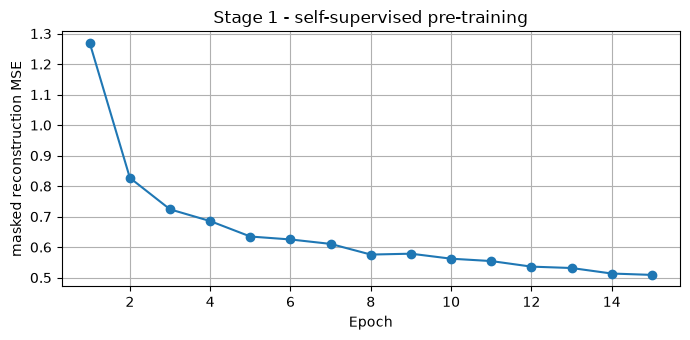

In [6]:
def block_mask(B: int, H: int, W: int, ratio: float, block: int) -> torch.Tensor:
    """(B,H,W) bool, True = hidden. Masks whole block x block squares."""
    m = (torch.rand(B, 1, math.ceil(H / block), math.ceil(W / block), device=device) < ratio).float()
    return F.interpolate(m, scale_factor=block, mode="nearest")[:, 0, :H, :W] > 0.5


def ssl_step(net, b):
    s2, s1 = b["s2"].clone(), b["s1"].clone()
    B, T, _, H, W = s2.shape
    target = torch.cat([s2[:, 0, :17], s1[:, 0, :3]], dim=1)
    valid2 = s2[:, 0, -1] > 0.5
    valid1 = s1[:, 0, -1] > 0.5
    m2 = block_mask(B, H, W, SSL_MASK_RATIO, SSL_BLOCK)
    m2[torch.rand(B, device=device) < SSL_DROP_S2_PROB] = True
    m1 = block_mask(B, H, W, SSL_MASK_RATIO * 0.6, SSL_BLOCK)
    s2[:, 0] = s2[:, 0] * (~m2)[:, None]
    s1[:, 0] = s1[:, 0] * (~m1)[:, None]
    with autocast():
        out = net({**b, "s2": s2, "s1": s1})
    rec = out["recon"].float()
    w2 = (m2 & valid2).float()
    w1 = (m1 & valid1).float()
    err2 = ((rec[:, :17] - target[:, :17]) ** 2).mean(1)
    err1 = ((rec[:, 17:] - target[:, 17:]) ** 2).mean(1)
    return (err2 * w2).sum() / w2.sum().clamp_min(1.0) + (err1 * w1).sum() / w1.sum().clamp_min(1.0)


ssl_history = []
if RUN_SSL and not SSL_PATH.exists():
    model = TemporalRadarFormer().to(device)
    steps_per_epoch = math.ceil(SSL_SAMPLES_PER_EPOCH / BATCH_SIZE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=SSL_LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=SSL_LR,
                                                    total_steps=SSL_EPOCHS * steps_per_epoch, pct_start=0.1)
    scaler = make_scaler()
    ssl_cfg = {"epochs": SSL_EPOCHS, "samples": SSL_SAMPLES_PER_EPOCH, "batch": BATCH_SIZE, "patch": PATCH,
               "lr": SSL_LR, "test_imagery": SSL_USE_TEST_IMAGERY, "n_context": N_CONTEXT}
    start_epoch = 1
    if RESUME and SSL_LAST.exists():
        st = torch.load(SSL_LAST, map_location=device, weights_only=False)
        if st.get("cfg") == ssl_cfg:
            model.load_state_dict(st["model"]); optimizer.load_state_dict(st["optimizer"])
            scheduler.load_state_dict(st["scheduler"]); scaler.load_state_dict(st["scaler"])
            ssl_history, start_epoch = st["history"], st["epoch"] + 1
            print(f"Resuming self-supervised stage from epoch {start_epoch}")

    print(f"Stage 1 (self-supervised): epochs {start_epoch}..{SSL_EPOCHS} | {steps_per_epoch} steps/epoch")
    for epoch in range(start_epoch, SSL_EPOCHS + 1):
        t0 = time.time()
        picks = ssl_index.sample(SSL_SAMPLES_PER_EPOCH, np.random.default_rng(SEED + 7000 + epoch))
        loader = make_loader(TemporalPatchDataset(ssl_scenes, ssl_index, picks, PATCH, train=True,
                                                  labels=False, jitter=PATCH // 4, seed=SEED + 7000 + epoch))
        model.train()
        running = 0.0
        for step, b in enumerate(loader, 1):
            b = to_dev(b)
            optimizer.zero_grad(set_to_none=True)
            loss = ssl_step(model, b)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            running += loss.item()
            if step % 25 == 0:
                print(f"  epoch {epoch} step {step}/{len(loader)} recon-MSE {running / step:.4f} "
                      f"({(time.time() - t0) / step:.2f}s/step)", end="\r")
        ssl_history.append(running / len(loader))
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                    "epoch": epoch, "history": ssl_history, "cfg": ssl_cfg}, SSL_LAST)
        print(f"SSL epoch {epoch:2d}/{SSL_EPOCHS} | recon-MSE {ssl_history[-1]:.4f} | {(time.time() - t0) / 60:.1f} min")

    torch.save({"model": model.state_dict(), "history": ssl_history, "cfg": ssl_cfg}, SSL_PATH)
    print(f"Self-supervised weights saved -> {SSL_PATH}")
    del model, optimizer, scheduler
    if device.type == "cuda":
        torch.cuda.empty_cache()
elif SSL_PATH.exists():
    ssl_history = torch.load(SSL_PATH, map_location="cpu", weights_only=False).get("history", [])
    print(f"Found {SSL_PATH} - skipping Stage 1.")
else:
    print("RUN_SSL = False - Stage 2 will train from random initialisation.")

if ssl_history:
    plt.figure(figsize=(7, 3.5))
    plt.plot(np.arange(1, len(ssl_history) + 1), ssl_history, marker="o")
    plt.xlabel("Epoch"); plt.ylabel("masked reconstruction MSE"); plt.title("Stage 1 - self-supervised pre-training")
    plt.grid(True); plt.tight_layout(); plt.show()

## 7. Stage 2: supervised fine-tuning

- Starts from the Stage 1 weights if they exist. The pre-trained part (stems, temporal fusion, spatial encoder) uses `ENCODER_LR_SCALE × MAX_LR`, while the decoder and heads use the full `MAX_LR`.
- AdamW with a one-cycle schedule (5% warm-up, cosine decay), gradient clipping at 1.0, and mixed precision.
- An **EMA copy** of the weights (decay 0.999) is kept and used for every validation and for the final checkpoint. Notebook 10's validation F1 jumped around by ±5 points between epochs; EMA smooths that out.
- Each epoch is validated on the same fixed patches of the two held-out training scenes. Checkpoint selection uses the better of *flat head* and *50/50 blended heads* macro-F1.

In [7]:
model = TemporalRadarFormer().to(device)
ssl_loaded = False
if SSL_PATH.exists():
    model.load_state_dict(torch.load(SSL_PATH, map_location=device, weights_only=False)["model"])
    ssl_loaded = True
print(f"Initialised from {'Stage 1 self-supervised weights' if ssl_loaded else 'scratch'}")

enc_ids = {id(p) for m in model.encoder_modules() for p in m.parameters()}
enc_params = [p for p in model.parameters() if id(p) in enc_ids]
dec_params = [p for p in model.parameters() if id(p) not in enc_ids]
enc_lr = MAX_LR * (ENCODER_LR_SCALE if ssl_loaded else 1.0)
optimizer = torch.optim.AdamW([{"params": enc_params, "lr": enc_lr},
                               {"params": dec_params, "lr": MAX_LR}], weight_decay=WEIGHT_DECAY)
steps_per_epoch = math.ceil(SAMPLES_PER_EPOCH / BATCH_SIZE)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[enc_lr, MAX_LR],
                                                total_steps=EPOCHS * steps_per_epoch, pct_start=WARMUP_FRAC)
scaler = make_scaler()

ema = copy.deepcopy(model).eval()
for p in ema.parameters():
    p.requires_grad_(False)


@torch.no_grad()
def ema_update(step: int):
    decay = min(EMA_DECAY, (1 + step) / (10 + step))
    for e, m in zip(ema.state_dict().values(), model.state_dict().values()):
        if e.dtype.is_floating_point:
            e.mul_(decay).add_(m.detach(), alpha=1 - decay)
        else:
            e.copy_(m)


run_cfg = {"epochs": EPOCHS, "samples": SAMPLES_PER_EPOCH, "batch": BATCH_SIZE, "patch": PATCH,
           "max_lr": MAX_LR, "val_scenes": VAL_SCENES, "n_context": N_CONTEXT, "ssl": ssl_loaded}
history = {"train_loss": [], "val_loss": [], "val_macro_f1": [], "val_macro_f1_blend": [], "val_f1": []}
start_epoch, best_score, global_step = 1, -1.0, 0

if RESUME and LAST_PATH.exists():
    st = torch.load(LAST_PATH, map_location=device, weights_only=False)
    if st.get("run_cfg") == run_cfg:
        model.load_state_dict(st["model"]); ema.load_state_dict(st["ema"])
        optimizer.load_state_dict(st["optimizer"]); scheduler.load_state_dict(st["scheduler"])
        scaler.load_state_dict(st["scaler"])
        history, best_score, global_step = st["history"], st["best_score"], st["global_step"]
        start_epoch = st["epoch"] + 1
        print(f"Resuming from epoch {start_epoch} (best val macro-F1 so far {100 * best_score:.2f})")
    else:
        print("Found a fine-tuning checkpoint from a different configuration - starting fresh.")

print(f"Stage 2 (fine-tuning): epochs {start_epoch}..{EPOCHS} | {steps_per_epoch} steps/epoch | "
      f"batch {BATCH_SIZE} | patch {PATCH} | encoder lr {enc_lr:.1e} | head lr {MAX_LR:.1e}")

for epoch in range(start_epoch, EPOCHS + 1):
    t0 = time.time()
    picks = train_index.sample(SAMPLES_PER_EPOCH, np.random.default_rng(SEED + 1000 * epoch))
    loader = make_loader(TemporalPatchDataset(train_scenes, train_index, picks, PATCH, train=True,
                                              jitter=GRID_STRIDE // 2, seed=SEED + epoch))
    model.train()
    running, parts_sum = 0.0, {}
    for step, b in enumerate(loader, 1):
        b = to_dev(b)
        optimizer.zero_grad(set_to_none=True)
        with autocast():
            out = model(b)
        loss, parts = criterion(out, b["y"])
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        global_step += 1
        ema_update(global_step)
        running += loss.item()
        for k, v in parts.items():
            parts_sum[k] = parts_sum.get(k, 0.0) + v
        if step % 25 == 0:
            print(f"  epoch {epoch} step {step}/{len(loader)} loss {running / step:.4f} "
                  f"({(time.time() - t0) / step:.2f}s/step)", end="\r")

    train_loss = running / len(loader)
    val_loss, cm_main, cm_blend = evaluate_patches(ema, val_loader)
    s_main, s_blend = macro_f1(cm_main), macro_f1(cm_blend)
    score = max(s_main, s_blend)
    f1 = prf(cm_blend if s_blend >= s_main else cm_main)[2]
    history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(s_main); history["val_macro_f1_blend"].append(s_blend)
    history["val_f1"].append([float(v) for v in f1])

    improved = score > best_score
    if improved:
        best_score = score
        torch.save({"model": ema.state_dict(), "epoch": epoch, "val_macro_f1": score}, BEST_PATH)
    torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch,
                "history": history, "best_score": best_score, "global_step": global_step,
                "run_cfg": run_cfg}, LAST_PATH)
    parts_txt = " ".join(f"{k} {v / len(loader):.3f}" for k, v in parts_sum.items())
    print(f"Epoch {epoch:2d}/{EPOCHS} | train {train_loss:.4f} ({parts_txt}) | val {val_loss:.4f} | "
          f"macro-F1 flat {100 * s_main:5.2f} blend {100 * s_blend:5.2f} | per-class "
          + " ".join(f"{100 * v:4.1f}" for v in f1)
          + f" | {(time.time() - t0) / 60:.1f} min{' *' if improved else ''}")

print(f"\nTraining complete. Best val macro-F1 (EMA): {100 * best_score:.2f} -> {BEST_PATH}")

Initialised from Stage 1 self-supervised weights
Stage 2 (fine-tuning): epochs 1..40 | 750 steps/epoch | batch 4 | patch 192 | encoder lr 1.8e-04 | head lr 6.0e-04
Epoch  1/40 | train 2.8598 (main 1.478 aux 1.224 coarse 0.888 ordinal 1.648) | val 1.6685 | macro-F1 flat 61.81 blend 61.39 | per-class 95.3 25.7 29.2 63.1 59.4 98.1 | 10.8 min *
Epoch  2/40 | train 1.4506 (main 0.723 aux 0.565 coarse 0.285 ordinal 1.110) | val 1.3065 | macro-F1 flat 67.96 blend 68.04 | per-class 96.8 42.6 42.0 64.9 63.6 98.4 | 10.7 min *
Epoch  3/40 | train 1.1506 (main 0.582 aux 0.491 coarse 0.213 ordinal 0.840) | val 1.1111 | macro-F1 flat 74.86 blend 75.17 | per-class 98.1 64.3 55.2 66.6 68.3 98.6 | 14.4 min *
Epoch  4/40 | train 1.0139 (main 0.520 aux 0.478 coarse 0.188 ordinal 0.688) | val 1.1039 | macro-F1 flat 76.78 blend 76.91 | per-class 98.4 68.8 57.0 68.7 70.0 98.7 | 16.2 min *
Epoch  5/40 | train 0.9480 (main 0.482 aux 0.449 coarse 0.164 ordinal 0.665) | val 1.0790 | macro-F1 flat 77.69 blend 77

## 8. Training curves

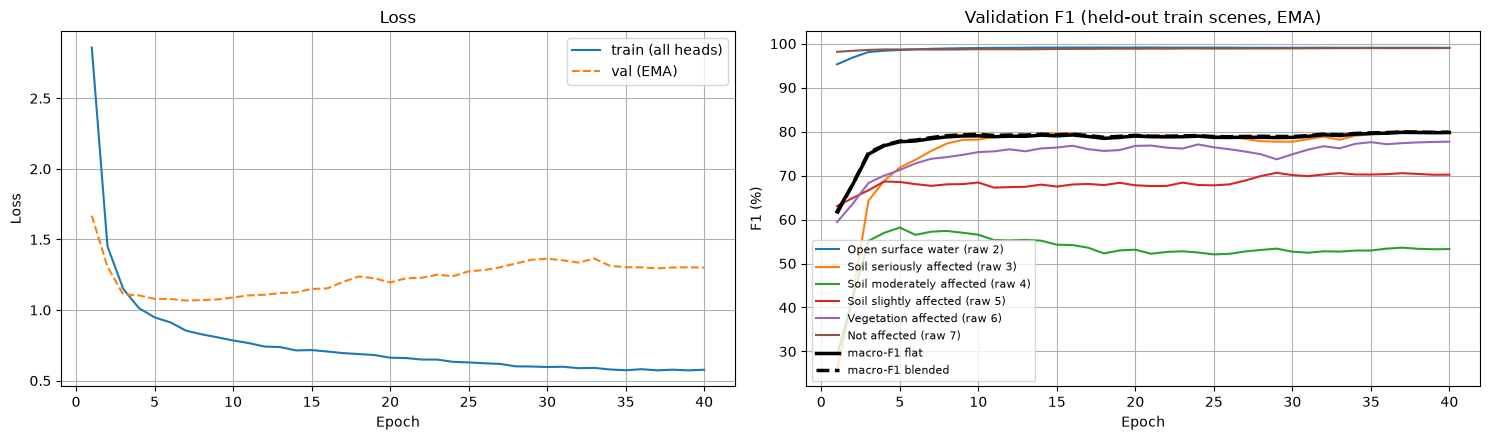

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
ep = np.arange(1, len(history["train_loss"]) + 1)
axes[0].plot(ep, history["train_loss"], label="train (all heads)")
axes[0].plot(ep, history["val_loss"], label="val (EMA)", linestyle="--")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Loss"); axes[0].legend(); axes[0].grid(True)

val_f1 = np.array(history["val_f1"])
for k in range(NUM_CLASSES):
    axes[1].plot(ep, 100 * val_f1[:, k], label=CLASS_NAMES[k])
axes[1].plot(ep, 100 * np.array(history["val_macro_f1"]), color="black", linewidth=2.5, label="macro-F1 flat")
axes[1].plot(ep, 100 * np.array(history["val_macro_f1_blend"]), color="black", linewidth=2.5,
             linestyle="--", label="macro-F1 blended")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("F1 (%)"); axes[1].set_title("Validation F1 (held-out train scenes, EMA)")
axes[1].legend(fontsize=8); axes[1].grid(True)
plt.tight_layout()
plt.show()

## 9. Ablation: how much do the time series and the radar contribute?

The *same trained network* is evaluated on the validation patches three times: with everything, with **all context dates removed** (target date only), and with **Sentinel-1 removed**. Context dates were randomly dropped during training, so the model has seen the no-context case and this is a fair comparison. Put this table in the report: it is the direct evidence for the design.

In [9]:
best = TemporalRadarFormer().to(device)
best.load_state_dict(torch.load(BEST_PATH, map_location=device, weights_only=False)["model"])
best.eval()

ablation = {}
for label, kw in [("full model", {}), ("no context dates", {"drop_context": True}), ("no Sentinel-1", {"drop_s1": True})]:
    _, cm_m, cm_b = evaluate_patches(best, val_loader, **kw)
    ablation[label] = {"macro_f1_flat": macro_f1(cm_m), "macro_f1_blend": macro_f1(cm_b),
                       "f1_blend": prf(cm_b)[2].tolist()}

short = ["Water", "Soil serious", "Soil moderate", "Soil slight", "Vegetation", "Not affected"]
print(f"{'Setting':<20}{'flat':>8}{'blend':>8}  " + "".join(f"{s:>15}" for s in short))
for label, r in ablation.items():
    print(f"{label:<20}{100 * r['macro_f1_flat']:>8.2f}{100 * r['macro_f1_blend']:>8.2f}  "
          + "".join(f"{100 * v:>15.2f}" for v in r["f1_blend"]))

Setting                 flat   blend            Water   Soil serious  Soil moderate    Soil slight     Vegetation   Not affected
full model             79.82   79.94            99.07          80.06          53.60          70.55          77.38          98.98
no context dates       79.72   79.86            99.06          79.89          53.50          70.40          77.34          98.98
no Sentinel-1          71.22   71.39            98.26          57.47          39.62          74.67          59.57          98.76


## 10. Full-scene inference, head blending and calibration

- Each scene is tiled into 512×512 centres. Every tile is predicted from a **640×640 window** (64 px margin, reflect-padded at scene borders) together with its context dates, and only the centre is kept, so there are no seams.
- **TTA**: `d4` averages all 8 flips/rotations, which costs 8× inference time. Use `"flip"` or `"none"` to go faster.
- **Calibration**, on the two held-out training scenes only, never on test:
  1. pick the head-blend weight α ∈ {0, 0.25, 0.5, 0.75, 1} that maximises macro-F1;
  2. fit a per-class additive logit bias by coordinate search, as in notebook 10.

In [10]:
def tile_starts(length: int, tile: int):
    starts = list(range(0, max(length - tile, 0) + 1, tile))
    if starts[-1] + tile < length:
        starts.append(length - tile)
    return starts


TTA_OPS = {"none": [(0, False)], "flip": [(0, False), (0, True)],
           "d4": [(k, f) for f in (False, True) for k in range(4)]}[TTA]


def _apply(x, k, flip):
    if flip:
        x = x.flip(-1)
    return torch.rot90(x, k, dims=(-2, -1)) if k else x


def _invert(x, k, flip):
    if k:
        x = torch.rot90(x, -k, dims=(-2, -1))
    return x.flip(-1) if flip else x


@torch.no_grad()
def predict_window(net, b):
    p_main = p_h = 0.0
    for k, flip in TTA_OPS:
        bb = {**b, "s2": _apply(b["s2"], k, flip), "s1": _apply(b["s1"], k, flip)}
        with autocast():
            out = net(bb)
        pm, ph = compose_probs(out)
        p_main = p_main + _invert(pm, k, flip)
        p_h = p_h + _invert(ph, k, flip)
    return p_main / len(TTA_OPS), p_h / len(TTA_OPS)


@torch.no_grad()
def scene_probs(net, sc: Scene, max_tiles=None):
    """Yield (r0, c0, p_flat (6,TILE,TILE), p_hier (6,TILE,TILE)) covering the whole scene."""
    net.eval()
    done = 0
    for r0 in tile_starts(sc.H, TILE):
        for c0 in tile_starts(sc.W, TILE):
            ra, rb = max(r0 - MARGIN, 0), min(r0 + TILE + MARGIN, sc.H)
            ca, cb = max(c0 - MARGIN, 0), min(c0 + TILE + MARGIN, sc.W)
            s2, s1, dt, doy, present = read_stack(sc, ra, ca, rb - ra, cb - ca)
            pad = ((0, 0), (0, 0), (MARGIN - (r0 - ra), MARGIN - (rb - r0 - TILE)),
                   (MARGIN - (c0 - ca), MARGIN - (cb - c0 - TILE)))
            b = {"s2": torch.from_numpy(np.pad(s2, pad, mode="reflect"))[None].to(device),
                 "s1": torch.from_numpy(np.pad(s1, pad, mode="reflect"))[None].to(device),
                 "dt": torch.from_numpy(dt)[None].to(device), "doy": torch.from_numpy(doy)[None].to(device),
                 "present": torch.from_numpy(present)[None].to(device)}
            pm, ph = predict_window(net, b)
            crop = (slice(None), slice(MARGIN, MARGIN + TILE), slice(MARGIN, MARGIN + TILE))
            yield r0, c0, pm[0][crop].cpu().numpy(), ph[0][crop].cpu().numpy()
            done += 1
            if max_tiles and done >= max_tiles:
                return


def blend_logp(pm, ph, alpha):
    return np.log((1 - alpha) * pm + alpha * ph + 1e-8)


def fit_logit_bias(logp: np.ndarray, y: np.ndarray, rounds: int = 3):
    grid = np.arange(-3.0, 3.01, 0.25, dtype=np.float32)
    bias = np.zeros(NUM_CLASSES, dtype=np.float32)
    best_s = macro_f1(confusion(y, logp.argmax(1)))
    for _ in range(rounds):
        for k in range(NUM_CLASSES):
            for v in grid:
                trial = bias.copy()
                trial[k] = v
                s = macro_f1(confusion(y, (logp + trial).argmax(1)))
                if s > best_s + 1e-6:
                    best_s, bias = s, trial
    return bias, best_s


# --- natural-distribution pixel sample from the held-out scenes ------------------------------
rng = np.random.default_rng(SEED)
cal_pm, cal_ph, cal_y = [], [], []
for sc in val_scenes:
    t0 = time.time()
    for r0, c0, pm, ph in scene_probs(best, sc, MAX_TILES):
        y = sc.gt[r0:r0 + TILE, c0:c0 + TILE]
        take = (y != IGNORE) & (rng.random(y.shape) < 0.05)
        cal_pm.append(pm[:, take].T); cal_ph.append(ph[:, take].T); cal_y.append(y[take])
    print(f"  {sc.name}: inference {(time.time() - t0) / 60:.1f} min")
cal_pm = np.concatenate(cal_pm).astype(np.float32)
cal_ph = np.concatenate(cal_ph).astype(np.float32)
cal_y = np.concatenate(cal_y)
print(f"Calibration sample: {len(cal_y):,} pixels")

alpha_scores = {a: macro_f1(confusion(cal_y, blend_logp(cal_pm, cal_ph, a).argmax(1)))
                for a in (0.0, 0.25, 0.5, 0.75, 1.0)}
ALPHA = max(alpha_scores, key=alpha_scores.get)
print("Held-out macro-F1 by head blend alpha (0 = flat head, 1 = hierarchical):",
      {a: round(100 * s, 2) for a, s in alpha_scores.items()}, "-> alpha =", ALPHA)

cal_logp = blend_logp(cal_pm, cal_ph, ALPHA)
logit_bias, cal_score = fit_logit_bias(cal_logp, cal_y)
print(f"Held-out macro-F1: blended {100 * alpha_scores[ALPHA]:.2f} -> + logit bias {100 * cal_score:.2f}")
print("Logit bias per class:", np.round(logit_bias, 2).tolist())
CAL_PATH.write_text(json.dumps({"alpha": ALPHA, "logit_bias": logit_bias.tolist(),
                                "alpha_scores": {str(a): s for a, s in alpha_scores.items()},
                                "class_names": CLASS_NAMES}, indent=2))
del cal_pm, cal_ph, cal_y, cal_logp

  BNPI_20230208: inference 3.6 min
  KNPI_20220310: inference 2.3 min
Calibration sample: 1,808,391 pixels
Held-out macro-F1 by head blend alpha (0 = flat head, 1 = hierarchical): {0.0: 79.6, 0.25: 79.62, 0.5: 79.66, 0.75: 79.69, 1.0: 79.56} -> alpha = 0.75
Held-out macro-F1: blended 79.69 -> + logit bias 80.81
Logit bias per class: [-1.0, -1.0, -1.25, -1.25, 0.75, 0.75]


## 11. Evaluation on the 9 test scenes

There are two rows per model:

- **raw**: flat head, plain argmax. This is the most direct comparison with notebook 10's raw row.
- **calibrated**: blended heads + logit bias, both fitted on held-out *training* scenes.

The last table compares against notebook 10's calibrated test results (numbers copied from its saved output).

In [11]:
test_scenes = all_test[:2] if QUICK_TEST else all_test

cm_raw = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
cm_cal = np.zeros_like(cm_raw)
pred_maps, per_scene = {}, {}
for sc in test_scenes:
    t0 = time.time()
    pred_raw = np.full((sc.H, sc.W), IGNORE, dtype=np.uint8)
    pred_cal = np.full((sc.H, sc.W), IGNORE, dtype=np.uint8)
    for r0, c0, pm, ph in scene_probs(best, sc, MAX_TILES):
        pred_raw[r0:r0 + TILE, c0:c0 + TILE] = pm.argmax(0)
        lp = blend_logp(pm, ph, ALPHA) + logit_bias[:, None, None]
        pred_cal[r0:r0 + TILE, c0:c0 + TILE] = lp.argmax(0)
    cm_raw += confusion(sc.gt, pred_raw)
    cm_scene = confusion(sc.gt, pred_cal)
    cm_cal += cm_scene
    pred_maps[sc.name] = pred_cal
    per_scene[sc.name] = {"macro_f1": macro_f1(cm_scene), "f1": prf(cm_scene)[2].tolist(),
                          "n_context": len(CONTEXT[sc.name])}
    print(f"  {sc.name}: {(time.time() - t0) / 60:.1f} min | context dates {len(CONTEXT[sc.name])} | "
          f"scene macro-F1 (calibrated) {100 * macro_f1(cm_scene):.2f}")

res_raw = report(cm_raw, "TEST SET - Temporal-Radar Former, flat head, raw argmax")
res_cal = report(cm_cal, f"TEST SET - Temporal-Radar Former, blended heads (alpha={ALPHA}) + logit bias")

NB10_CAL_F1 = [98.62, 71.04, 60.20, 63.54, 67.22, 98.56]     # notebook 10, calibrated, test set
NB10_MACRO, NB10_WEIGHTED = 76.53, 81.53
print("\nPer-class F1 (%) - notebook 10 (Spectral ResUNet, calibrated) vs notebook 11 (TRF)")
print(f"{'Class':<36}{'NB10':>9}{'TRF raw':>10}{'TRF cal':>10}{'gain':>9}")
for k in range(NUM_CLASSES):
    c = 100 * res_cal["f1"][k]
    print(f"{CLASS_NAMES[k]:<36}{NB10_CAL_F1[k]:>9.2f}{100 * res_raw['f1'][k]:>10.2f}{c:>10.2f}{c - NB10_CAL_F1[k]:>+9.2f}")
print(f"{'MACRO-F1 (6 classes)':<36}{NB10_MACRO:>9.2f}{100 * res_raw['macro_f1_all']:>10.2f}"
      f"{100 * res_cal['macro_f1_all']:>10.2f}{100 * res_cal['macro_f1_all'] - NB10_MACRO:>+9.2f}")
print(f"{'Pixel-weighted F1, raw 2-6':<36}{NB10_WEIGHTED:>9.2f}{100 * res_raw['weighted_water'][2]:>10.2f}"
      f"{100 * res_cal['weighted_water'][2]:>10.2f}{100 * res_cal['weighted_water'][2] - NB10_WEIGHTED:>+9.2f}")
print("Paper Table 1 best (RUPNet), pixel-weighted F1 raw 2-6: 81.19")

RESULTS_PATH.write_text(json.dumps({
    "model": "Temporal-Radar Former (notebook 11)", "quick_test": QUICK_TEST, "ssl_pretrained": ssl_loaded,
    "alpha": ALPHA, "logit_bias": logit_bias.tolist(), "test_raw": res_raw, "test_calibrated": res_cal,
    "per_scene": per_scene, "val_ablation": ablation, "best_val_macro_f1": best_score,
    "confusion_calibrated": cm_cal.tolist(), "config": {**run_cfg, "tta": TTA, "tile": TILE, "margin": MARGIN},
}, indent=2))
print(f"\nSaved all numbers -> {RESULTS_PATH}")

  BNPI_20220208: 3.5 min | context dates 0 | scene macro-F1 (calibrated) 80.17
  BNPI_20220325: 3.9 min | context dates 1 | scene macro-F1 (calibrated) 81.53
  BNPI_20231125: 3.5 min | context dates 0 | scene macro-F1 (calibrated) 65.23
  BNPI_20240129: 4.2 min | context dates 2 | scene macro-F1 (calibrated) 80.67
  KNPI_20230213: 2.0 min | context dates 0 | scene macro-F1 (calibrated) 77.02
  KNPI_20230603: 2.2 min | context dates 1 | scene macro-F1 (calibrated) 64.14
  KNPI_20240104: 2.0 min | context dates 0 | scene macro-F1 (calibrated) 56.77
  KNPI_20240129: 2.2 min | context dates 1 | scene macro-F1 (calibrated) 62.20
  KNPI_20240203: 2.4 min | context dates 2 | scene macro-F1 (calibrated) 78.39

TEST SET - Temporal-Radar Former, flat head, raw argmax
Cls Name                                   Pr (%)   Rc (%)   F1 (%)          Pixels
--------------------------------------------------------------------------------------
0   Open surface water (raw 2)              98.46    98.89   

## 12. Confusion matrix

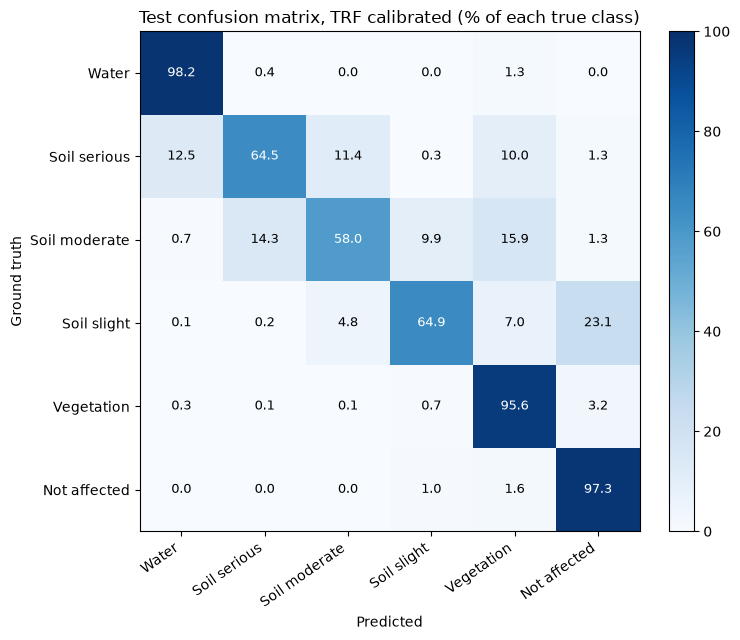

In [12]:
cm_pct = 100 * cm_cal / np.maximum(cm_cal.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(short, rotation=35, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(short)
ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth")
ax.set_title("Test confusion matrix, TRF calibrated (% of each true class)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm_pct[i, j]:.1f}", ha="center", va="center",
                color="white" if cm_pct[i, j] > 55 else "black", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 13. Prediction maps

For up to three test scenes, the 512×512 window richest in affected soil is shown four ways: the target date in true colour, the most recent context date in true colour (what the model "remembers"), the ground truth, and the calibrated prediction.

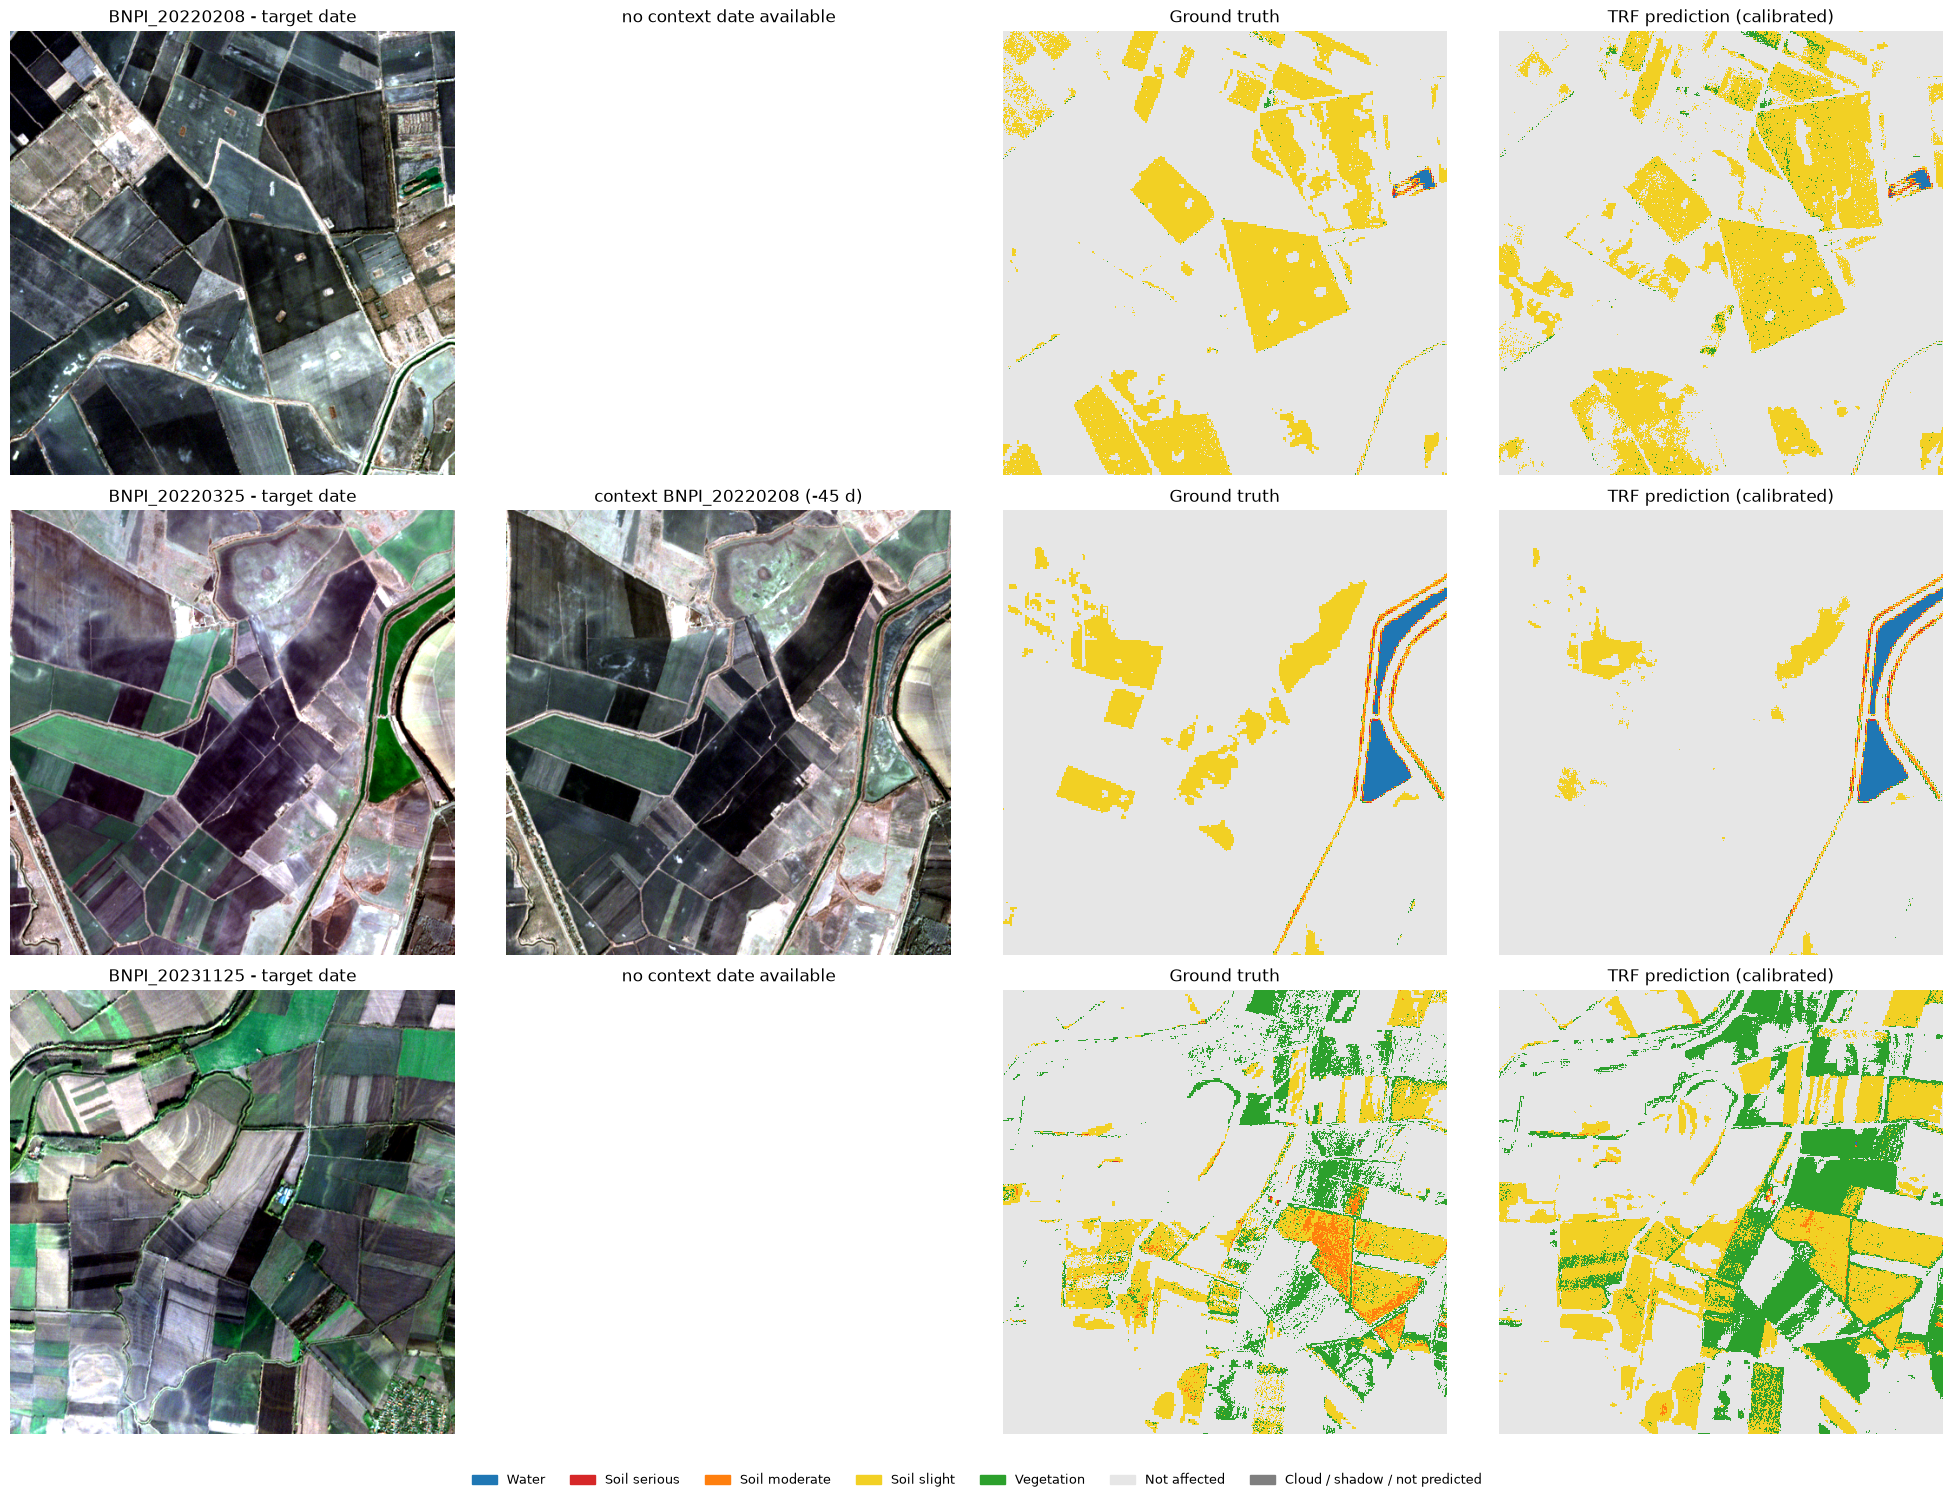

In [13]:
PALETTE = ["#1f77b4", "#d62728", "#ff7f0e", "#f2d024", "#2ca02c", "#e6e6e6", "#7f7f7f"]
cmap = ListedColormap(PALETTE)


def to_display(label_map: np.ndarray) -> np.ndarray:
    return np.where(label_map == IGNORE, NUM_CLASSES, label_map)


def stretch_rgb(rgb: np.ndarray) -> np.ndarray:
    out = np.empty_like(rgb, dtype=np.float32)
    for k in range(3):
        lo, hi = np.percentile(rgb[..., k], [2, 98])
        out[..., k] = np.clip((rgb[..., k] - lo) / (hi - lo + 1e-8), 0, 1)
    return out


shown = [sc for sc in test_scenes if sc.name in pred_maps][:3]
fig, axes = plt.subplots(len(shown), 4, figsize=(20, 5 * len(shown)), squeeze=False)
for row, sc in enumerate(shown):
    pred = pred_maps[sc.name]
    block = 256
    soil = ((sc.gt >= 1) & (sc.gt <= 3)) & (pred != IGNORE)
    hb, wb = sc.H // block, sc.W // block
    counts = soil[:hb * block, :wb * block].reshape(hb, block, wb, block).sum((1, 3))
    bi, bj = np.unravel_index(counts.argmax(), counts.shape)
    r0 = int(np.clip(bi * block - 128, 0, sc.H - 512))
    c0 = int(np.clip(bj * block - 128, 0, sc.W - 512))
    s2, _ = sc.read(r0, c0, 512, 512)
    axes[row, 0].imshow(stretch_rgb(np.stack([s2[3], s2[2], s2[1]], -1).astype(np.float32)))
    axes[row, 0].set_title(f"{sc.name} - target date")
    if CONTEXT[sc.name]:
        ctx = CONTEXT[sc.name][0]
        s2c, _ = ctx.read(r0, c0, 512, 512)
        axes[row, 1].imshow(stretch_rgb(np.stack([s2c[3], s2c[2], s2c[1]], -1).astype(np.float32)))
        axes[row, 1].set_title(f"context {ctx.name} (-{(sc.date - ctx.date).days} d)")
    else:
        axes[row, 1].set_title("no context date available")
    axes[row, 2].imshow(to_display(sc.gt[r0:r0 + 512, c0:c0 + 512]), cmap=cmap, vmin=0, vmax=NUM_CLASSES,
                        interpolation="nearest")
    axes[row, 2].set_title("Ground truth")
    axes[row, 3].imshow(to_display(pred[r0:r0 + 512, c0:c0 + 512]), cmap=cmap, vmin=0, vmax=NUM_CLASSES,
                        interpolation="nearest")
    axes[row, 3].set_title("TRF prediction (calibrated)")
    for a in axes[row]:
        a.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[k]) for k in range(NUM_CLASSES + 1)]
fig.legend(handles, short + ["Cloud / shadow / not predicted"], loc="lower center", ncol=7, fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 14. Summary: fill in after running

| | Notebook 10 (calibrated) | Notebook 11 TRF (calibrated) | Notebook 11 TRF (raw) |
|---|---|---|---|
| Water F1 | 98.62 | 98.40 | 98.68 |
| Soil seriously affected F1 | 71.04 | 67.43 | 70.04 |
| Soil moderately affected F1 | 60.20 | 57.77 | 61.82 |
| Soil slightly affected F1 | 63.54 | 56.44 | 56.80 |
| Vegetation affected F1 | 67.22 | 64.18 | 67.86 |
| Not affected F1 | 98.56 | 98.41 | 98.31 |
| Macro-F1 (6 classes) | 76.53 | 73.77 | 75.59 |
| Pixel-weighted F1, raw 2–6 (paper Table 1: 81.19) | 81.53 | 79.00 | 80.30 |

**Ablation (§9, validation):** full model 79.94% / no context dates 79.86% / no Sentinel-1 71.39%

**Settings to report:** self-supervised pre-training ON (15 epochs), SSL_USE_TEST_IMAGERY = False, TTA mode d4, blend α = 0.75, GPU NVIDIA RTX 4050 (6GB) and wall-clock time ~6.5h. All of these are also saved in outputs/trf_results.json.

**If a class is still weak, next levers in order:** (1) more Stage 1 epochs; (2) N_CONTEXT = 4 with MAX_GAP_DAYS = 180; (3) an ensemble with notebook 10 (average the calibrated probabilities); (4) external elevation data (Copernicus DEM + topographic wetness index) as extra per-pixel channels.
